# SAE OPTIMISATION NUMÉRIQUE
## Supply Chain : Un benchmark de méthodes d'optimisation de descente

**ING2 Mathématiques pour les Data**

**CY Tech – Année universitaire 2026-2027 - Carlot Lionel, Laforest Pierre**

---


# Partie A — Étude du problème et de ses propriétés

## A.1 — Modélisation de la fonction objectif

On considère un problème de localisation d'un centre logistique destiné à desservir $n=12$ clients.

Chaque client $i$ est caractérisé par :
- Sa position $a_i=(u_i,v_i)\in\mathbb{R}^2$.
- Son poids $w_i>0$, représentant son importance économique ou son volume de marchandises.

On cherche à déterminer la position $x=(x_1,x_2)$ du centre logistique minimisant le coût total de transport.

La fonction objectif est définie par :

$$
\boxed{
f(x)=\sum_{i=1}^{n}w_i\|x-a_i\|_2
}
$$

où :

$$
\|x-a_i\|_2=
\sqrt{(x_1-u_i)^2+(x_2-v_i)^2}
$$

Le problème d'optimisation s'écrit donc :

$$
\boxed{
\min_{x\in\mathbb{R}^2}f(x)
}
$$



In [1]:
import numpy as np
import matplotlib.pyplot as plt

# A est un tableau qui contient les coordonnées de tous clients sous forme d'un doublet 
A = np.array([
    [1, 2], [2, 7], [4, 4], [5, 1],
    [7, 6], [8, 3], [9, 8], [3, 9],
    [6, 8], [10, 5], [0, 6], [7, 0]
], dtype=float)

# W représente le poids des clients
w = np.array([5, 3, 8, 6, 4, 10, 2, 5, 7, 4, 2, 3])

def f(x):
    distances = np.linalg.norm(A - x, axis=1)
    return np.sum(w * distances)


## A.2 — Représentation des sites clients

Le graphique représente les positions géographiques des 12 clients.

La taille des points est proportionnelle au poids $w_i$ de chaque client.

**Observations :**

- Les clients sont répartis dans un espace bidimensionnel.
- Les poids sont différents selon les clients.
- Le client 6 possède le poids le plus élevé ($w_6=10$).
- Les clients ayant des poids importants contribuent davantage au coût total de transport.

Ainsi, la position optimale du centre logistique dépend à la fois des distances aux clients et de leurs poids respectifs.

On s'attend donc à ce que le centre optimal soit influencé davantage par les clients les plus importants.


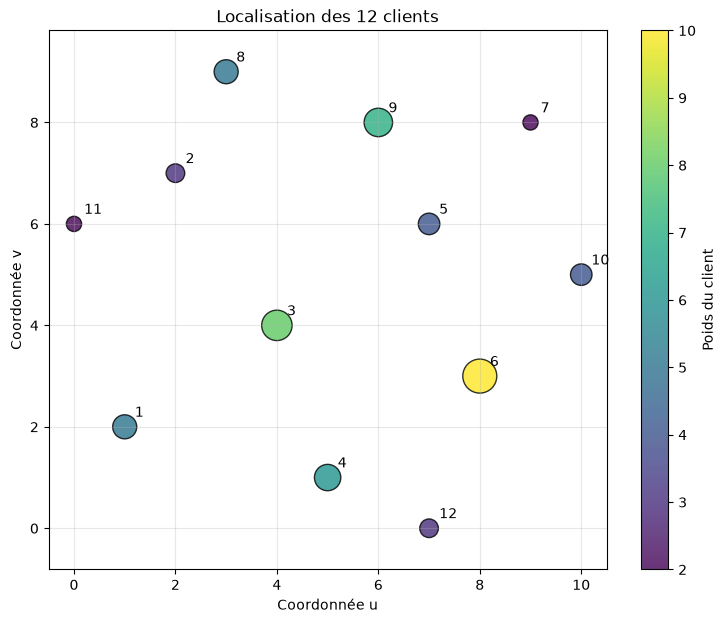

In [2]:
plt.figure(figsize=(9, 7))

plt.scatter(
    A[:, 0], A[:, 1],
    s=60*w,
    c=w,
    cmap="viridis",
    edgecolors="black",
    alpha=0.8
)

for i in range(len(A)):
    plt.annotate(
        str(i+1),
        (A[i, 0]+0.2, A[i, 1]+0.2)
    )

plt.colorbar(label="Poids du client")
plt.xlabel("Coordonnée u")
plt.ylabel("Coordonnée v")
plt.title("Localisation des 12 clients")
plt.grid(alpha=0.3)
plt.axis("equal")
plt.show()


## A.3 — Étude des propriétés mathématiques

### 1. Convexité

La fonction objectif est :

$$
f(x)=\sum_{i=1}^{n}w_i\|x-a_i\|_2
$$

La norme euclidienne est une fonction convexe.

Par conséquent, pour chaque client $i$, la fonction :

$$
g_i(x)=\|x-a_i\|_2
$$

est convexe sur $\mathbb{R}^2$.

Comme les poids $w_i$ sont strictement positifs, les fonctions produits de $w_i g_i$ sont également convexes.

Or, une somme de fonctions convexes est convexe.

On en déduit :

$$
\boxed{f\text{ est convexe sur }\mathbb{R}^2}
$$

la convexité de $f$ nous permet de déduire que tout minimum local de $f$ est également un minimum global.

### 2. Différentiabilité

Pour $x\neq a_i$, la fonction $g_i$ est différentiable et son gradient vaut :

$$
\nabla g_i(x)=\frac{x-a_i}{\|x-a_i\|_2}
$$

Ainsi, lorsque $x$ ne coïncide avec aucun site client :

$$
\boxed{
\nabla f(x)=
\sum_{i=1}^{n}
w_i\frac{x-a_i}{\|x-a_i\|_2}
}
$$

En revanche, lorsque $x=a_i$, le terme $\|x-a_i\|_2$ n'est pas différentiable.

La fonction objectif n'est donc pas différentiable aux positions des clients.

Ainsi nous pouvant en déduire que les méthodes d'optimisations utilisant directement le gradient ou la Hessienne nécessitent des précautions particulières.

### 3. Existence d'un minimiseur

La fonction $f$ est continue sur $\mathbb{R}^2$, car elle est une somme de fonctions continues.

D'après l'inégalité triangulaire :

$$
\|x-a_i\|_2\geq\|x\|_2-\|a_i\|_2
$$

En multipliant par $w_i$ et en additionant :

$$
f(x)\geq
\left(\sum_{i=1}^{n}w_i\right)\|x\|_2
-
\sum_{i=1}^{n}w_i\|a_i\|_2
$$

Or les poids étant tous strictement positifs :

$$
\sum_{i=1}^{n}w_i>0
$$

On obtient :

$$
\lim_{\|x\|_2\to+\infty}f(x)=+\infty
$$

La fonction $f$ est donc coercive.

Étant continue et coercive sur $\mathbb{R}^2$, elle admet au moins un minimiseur global.

### 4. Unicité du minimiseur

La convexité seule ne garantit pas l'unicité du minimiseur.

Cependant, dans notre jeu de données, les positions des clients ne sont pas toutes alignées.

Pour deux points distincts $x$ et $y$, l'inégalité triangulaire appliquée à chaque distance est stricte pour au moins un client, puisque les sites ne sont pas tous sur la droite passant par $x$ et $y$.

Comme tous les poids sont positifs, la somme est strictement convexe.

Ainsi :

$$
\boxed{f\text{ est strictement convexe}}
$$

On en déduit que le minimiseur global est unique.

Conclusion :

La fonction objectif est continue, strictement convexe et coercive, mais non différentiable aux positions des clients.

Le problème possède donc un unique minimiseur global.



## A.4 — Définition des critères d'arrêt

Pour comparer les performances des méthodes d'optimisation, plusieurs critères d'arrêt peuvent être utilisés.

### 1. Norme du gradient

Pour une fonction différentiable, on peut arrêter l'algorithme lorsque :

$$
\|\nabla f_\gamma(x_k)\|_2<\varepsilon_g
$$

Ce critère permet de vérifier que l'on se rapproche suffisament près d'un point stationnaire.

### 2. Variation des itérés

On peut également arrêter les calculs lorsque :

$$
\|x_{k+1}-x_k\|_2<\varepsilon_x
$$

Cela signifie que la position du centre varie très peu entre deux itérations.

### 3. Variation de la fonction objectif

Un autre critère consiste à vérifier :

$$
|f_\gamma(x_{k+1})-f_\gamma(x_k)|<\varepsilon_f
$$

Il indique que le coût de transport varie très peu.

### 4. Nombre maximal d'itérations

On impose un nombre maximal d'itérations :

$$
k\geq k_{\max}
$$

Ce critère permet d'éviter des temps de calcul excessifs en cas de convergence lente ou d'échec.

### Paramètres retenus

Pour les premières expériences, nous choisissons :

$$
\varepsilon_g= faut voir avec pierre
$$

$$
\varepsilon_x= faut voir avec pierre
$$

$$
\varepsilon_f=faut voir avec pierre
$$

$$
k_{\max}=faut voir avec pierre
$$

Ces paramètres pourront être adaptés selon les méthodes étudiées.





## Définition et justification des critères d'arrêt

### 1. Objectif

Dans cette étude, nous cherchons à comparer plusieurs algorithmes de descente pour résoudre le problème de Fermat-Weber :

$$
\min_{x\in\mathbb{R}^2} f(x)
=
\sum_{i=1}^{n} w_i\|x-a_i\|_2.
$$

Pour les méthodes nécessitant une fonction différentiable, nous utilisons l'approximation lissée :

$$
f_\gamma(x)
=
\sum_{i=1}^{n}
w_i\sqrt{\|x-a_i\|_2^2+\gamma},
\qquad \gamma>0.
$$

Afin d'assurer une comparaison reproductible, il est nécessaire de définir des critères d'arrêt communs, tout en tenant compte des particularités de chaque méthode.

### 2. Critère de stationnarité

Pour une fonction convexe et différentiable, la condition

$$
\nabla f_\gamma(x^*)=0
$$

est nécessaire et suffisante pour que $x^*$ soit un minimiseur global.

Nous considérons donc le critère :

$$
\boxed{
\|\nabla f_\gamma(x^{(k)})\|_2
\leq \varepsilon_g
}
$$

où $\varepsilon_g>0$ représente la tolérance sur la stationnarité.

Ce critère mesure la proximité de la condition d'optimalité, mais ne fournit pas à lui seul une borne universelle sur la distance au minimiseur.

### 3. Critères de stagnation

Deux critères complémentaires permettent de détecter une stagnation numérique.

**Variation des itérés :**

$$
\boxed{
\|x^{(k+1)}-x^{(k)}\|_2
\leq
\varepsilon_x
}
$$

**Variation relative de la fonction objectif :**

$$
\boxed{
\frac{
|f_\gamma(x^{(k+1)})-f_\gamma(x^{(k)})|
}{
\max(1,|f_\gamma(x^{(k)})|)
}
\leq\varepsilon_f
}
$$

Une faible variation des itérés ou de la fonction objectif ne garantit toutefois pas que l'optimum soit atteint.

Ces deux conditions sont donc utilisées pour identifier une éventuelle stagnation et non pour certifier la convergence.

### 4. Justification par la convexité

Puisque $f_\gamma$ est convexe et différentiable, nous disposons de l'inégalité :

$$
f_\gamma(y)\geq
f_\gamma(x)+
\nabla f_\gamma(x)^\top(y-x).
$$

En choisissant $y=x_\gamma^*$, où $x_\gamma^*$ est un minimiseur de $f_\gamma$, nous obtenons :

$$
f_\gamma(x)-f_\gamma(x_\gamma^*)
\leq
\nabla f_\gamma(x)^\top(x-x_\gamma^*).
$$

Or, un minimiseur de $f_\gamma$ appartient à l'enveloppe convexe des sites clients :

$$
x_\gamma^*\in
\operatorname{conv}\{a_1,\ldots,a_n\}.
$$

Par conséquent :

$$
\nabla f_\gamma(x)^\top(x-x_\gamma^*)
\leq
\max_{1\leq i\leq n}
\nabla f_\gamma(x)^\top(x-a_i).
$$

Nous obtenons ainsi :

$$
\boxed{
0\leq f_\gamma(x)-f_\gamma(x_\gamma^*)
\leq G_\gamma(x)
}
$$

avec :

$$
\boxed{
G_\gamma(x)=
\max_{1\leq i\leq n}
\nabla f_\gamma(x)^\top(x-a_i)
}
$$

Cette quantité est calculable sans connaître le minimiseur exact.

Nous retenons donc comme critère principal d'optimalité :

$$
\boxed{
G_\gamma(x^{(k)})\leq
\varepsilon_{\mathrm{opt}}
}
$$

Ce critère fournit une majoration de l'écart à la valeur optimale de la fonction lissée.

### 5. Choix des tolérances

Nous fixons une erreur maximale cible sur la valeur optimale lissée :

$$
\varepsilon_{\mathrm{opt}}=10^{-5}.
$$

Les autres tolérances sont initialement fixées à :

$$
\begin{aligned}
\varepsilon_g &= 10^{-7},\\
\varepsilon_x &= 10^{-8},\\
\varepsilon_f &= 10^{-10},\\
k_{\max} &= 10000.
\end{aligned}
$$

Ces paramètres constituent un protocole expérimental initial. Leur pertinence sera évaluée par une étude de sensibilité.

Le nombre maximal d'itérations constitue une sécurité contre les calculs excessivement longs. Il ne représente pas un critère de convergence.

### 6. Distinction entre convergence et stagnation

Un algorithme est déclaré **convergent à la précision demandée** lorsque :

$$
G_\gamma(x^{(k)})\leq\varepsilon_{\mathrm{opt}}.
$$

Si la variation des itérés ou de la fonction objectif devient trop faible sans satisfaire ce critère, l'arrêt est classé comme une stagnation numérique.

Si le nombre maximal d'itérations est atteint, la convergence n'est pas considérée comme certifiée.

Cette distinction permet de comparer les méthodes sans confondre arrêt numérique et atteinte de la précision souhaitée.


In [3]:

import numpy as np

# ===================================================
# Paramètres communs du benchmark
# ===================================================

tol_grad = 1e-7      # Tolérance de stationnarité
tol_x = 1e-8         # Tolérance sur les déplacements
tol_f = 1e-10        # Tolérance relative sur f_gamma
tol_opt = 1e-5       # Erreur maximale cible sur f_gamma
max_iter = 10000     # Nombre maximal d'itérations

print("Critères d'arrêt retenus :")
print(f"  Gradient        : {tol_grad:.1e}")
print(f"  Déplacement     : {tol_x:.1e}")
print(f"  Variation de f  : {tol_f:.1e}")
print(f"  Optimalité      : {tol_opt:.1e}")
print(f"  Itérations max. : {max_iter}")


Critères d'arrêt retenus :
  Gradient        : 1.0e-07
  Déplacement     : 1.0e-08
  Variation de f  : 1.0e-10
  Optimalité      : 1.0e-05
  Itérations max. : 10000


In [4]:
tol_grad = 1e-6
tol_x = 1e-8
tol_f = 1e-10
max_iter = 10000


# Partie B — Lissage de la fonction objectif

## B.1 — Différentiabilité et calcul du gradient

La fonction objectif originale n'est pas différentiable aux positions des clients.

Pour pouvoir utiliser les méthodes de descente classiques, on introduit une fonction lissée :

$$
\boxed{
f_\gamma(x)=
\sum_{i=1}^{n}
w_i\sqrt{\|x-a_i\|_2^2+\gamma}
}
$$

avec $\gamma>0$.

### 1. Différentiabilité

Pour chaque client, on pose :

$$
d_i(x)=(x_1-u_i)^2+(x_2-v_i)^2+\gamma
$$

Puisque $\gamma>0$, on a :

$$
d_i(x)>0
$$

La fonction racine carrée est différentiable sur $]0,+\infty[$.

Par composition et somme de fonctions différentiables, $f_\gamma$ est différentiable sur $\mathbb{R}^2$.

### 2. Calcul du gradient

On a :

$$
f_\gamma(x)=\sum_{i=1}^{n}w_i\sqrt{d_i(x)}
$$

En dérivant par rapport à $x_1$ :

$$
\frac{\partial f_\gamma}{\partial x_1}
=
\sum_{i=1}^{n}
w_i\frac{x_1-u_i}{\sqrt{d_i(x)}}
$$

De même :

$$
\frac{\partial f_\gamma}{\partial x_2}
=
\sum_{i=1}^{n}
w_i\frac{x_2-v_i}{\sqrt{d_i(x)}}
$$

On obtient donc :

$$
\boxed{
\nabla f_\gamma(x)=
\sum_{i=1}^{n}
w_i\frac{x-a_i}
{\sqrt{\|x-a_i\|_2^2+\gamma}}
}
$$

Ce gradient est défini pour tout $x\in\mathbb{R}^2$.

Lorsque $\gamma\to0^+$, la fonction lissée se rapproche de la fonction objectif originale.



## B.2 — Calcul de la Hessienne

La Hessienne correspond à la matrice des dérivées partielles secondes de la fonction objectif.

On rappelle :

$$
\nabla f_\gamma(x)=
\sum_{i=1}^{n}
w_i\frac{x-a_i}
{\sqrt{\|x-a_i\|_2^2+\gamma}}
$$

On pose :

$$
d_i(x)=(x_1-u_i)^2+(x_2-v_i)^2+\gamma
$$

### 1. Dérivées secondes diagonales

En dérivant par rapport à $x_1$ :

$$
\frac{\partial^2 f_\gamma}{\partial x_1^2}
=
\sum_{i=1}^{n}w_i
\left(
\frac{1}{\sqrt{d_i(x)}}-
\frac{(x_1-u_i)^2}{d_i(x)^{3/2}}
\right)
$$

De même :

$$
\frac{\partial^2 f_\gamma}{\partial x_2^2}
=
\sum_{i=1}^{n}w_i
\left(
\frac{1}{\sqrt{d_i(x)}}-
\frac{(x_2-v_i)^2}{d_i(x)^{3/2}}
\right)
$$

### 2. Dérivées secondes croisées

On obtient :

$$
\frac{\partial^2 f_\gamma}{\partial x_1\partial x_2}
=
-\sum_{i=1}^{n}w_i
\frac{(x_1-u_i)(x_2-v_i)}
{d_i(x)^{3/2}}
$$

Les dérivées croisées sont égales puisque $f_\gamma$ est de classe $C^2$.

### 3. Expression matricielle

La Hessienne s'écrit :

$$
\boxed{
\nabla^2 f_\gamma(x)=
\sum_{i=1}^{n}w_i
\left[
\frac{I_2}{\sqrt{\|x-a_i\|_2^2+\gamma}}
-
\frac{(x-a_i)(x-a_i)^T}
{(\|x-a_i\|_2^2+\gamma)^{3/2}}
\right]
}
$$

où $I_2$ désigne la matrice identité de taille 2.

### 4. Propriété de la Hessienne

Pour tout vecteur $z\neq0$, on obtient :

$$
z^T\nabla^2 f_\gamma(x)z
=
\sum_{i=1}^{n}
w_i
\frac{
(\|x-a_i\|_2^2+\gamma)\|z\|_2^2
-
((x-a_i)^Tz)^2
}{
(\|x-a_i\|_2^2+\gamma)^{3/2}
}
$$

D'après l'inégalité de Cauchy-Schwarz :

$$
((x-a_i)^Tz)^2
\leq\|x-a_i\|_2^2\|z\|_2^2
$$

Ainsi :

$$
z^T\nabla^2 f_\gamma(x)z
\geq
\sum_{i=1}^{n}
w_i
\frac{\gamma\|z\|_2^2}
{(\|x-a_i\|_2^2+\gamma)^{3/2}}
>0
$$

La Hessienne est donc définie positive.

Conclusion : pour $\gamma>0$, la fonction $f_\gamma$ est strictement convexe et possède un unique minimiseur global.



## B.3 — Implémentation des méthodes d'optimisation

Nous comparons quatre méthodes de descente appliquées à la fonction lissée $f_\gamma$.

### 1. Gradient à pas fixe

La méthode du gradient consiste à se déplacer dans la direction opposée au gradient :

$$
\boxed{
x_{k+1}=x_k-\rho\nabla f_\gamma(x_k)
}
$$

où $\rho>0$ est le pas d'apprentissage.

Un pas trop faible entraîne une convergence lente, tandis qu'un pas trop élevé peut provoquer des oscillations ou une divergence.

### 2. Gradient avec recherche linéaire d'Armijo

Cette méthode adapte le pas à chaque itération.

On choisit la direction :

$$
d_k=-\nabla f_\gamma(x_k)
$$

Puis un pas $\alpha_k$ vérifiant :

$$
f_\gamma(x_k+\alpha_kd_k)
\leq
f_\gamma(x_k)
+c\alpha_k\nabla f_\gamma(x_k)^Td_k
$$

avec $0<c<1$.

La recherche linéaire permet de garantir une diminution suffisante de la fonction objectif.

### 3. Méthode de Newton

La méthode de Newton exploite les informations du gradient et de la Hessienne.

La direction est obtenue en résolvant :

$$
\nabla^2f_\gamma(x_k)d_k
=
-\nabla f_\gamma(x_k)
$$

Puis :

$$
\boxed{
x_{k+1}=x_k+\alpha_kd_k
}
$$

La méthode peut converger très rapidement près du minimiseur, mais nécessite le calcul et la résolution d'un système impliquant la Hessienne.

Une recherche linéaire d'Armijo est utilisée pour sécuriser les déplacements.

### 4. Méthode quasi-Newton BFGS

La méthode BFGS évite de calculer explicitement la Hessienne à chaque itération.

Elle construit progressivement une approximation $B_k$ de l'inverse de la Hessienne.

La direction de descente est :

$$
d_k=-B_k\nabla f_\gamma(x_k)
$$

On définit :

$$
s_k=x_{k+1}-x_k
$$

$$
y_k=\nabla f_\gamma(x_{k+1})-\nabla f_\gamma(x_k)
$$

Puis :

$$
\rho_k=\frac{1}{y_k^Ts_k}
$$

La mise à jour BFGS est :

$$
B_{k+1}=
(I-\rho_ks_ky_k^T)B_k
(I-\rho_ky_ks_k^T)
+\rho_ks_ks_k^T
$$

Cette méthode cherche à combiner la rapidité des méthodes de Newton avec un coût de calcul réduit par itération.


In [5]:
def f_gamma(x, gamma):
    d2 = np.sum((A - x)**2, axis=1)
    return np.sum(w * np.sqrt(d2 + gamma))


def grad_f_gamma(x, gamma):
    diff = x - A
    d = np.sqrt(np.sum(diff**2, axis=1) + gamma)

    return np.sum(
        w[:, None] * diff / d[:, None],
        axis=0
    )


def hess_f_gamma(x, gamma):
    H = np.zeros((2, 2))
    I = np.eye(2)

    for i in range(len(A)):
        diff = x - A[i]
        d2 = np.dot(diff, diff) + gamma

        H += w[i] * (
            I / np.sqrt(d2)
            - np.outer(diff, diff) / d2**1.5
        )

    return H

In [6]:
def gradient_fixe(x0, gamma, rho=0.01,
                  tol=1e-6, max_iter=10000):

    x = np.array(x0, dtype=float)
    historique = [f_gamma(x, gamma)]

    for k in range(max_iter):
        g = grad_f_gamma(x, gamma)

        if np.linalg.norm(g) < tol:
            break

        x = x - rho * g
        historique.append(f_gamma(x, gamma))

    return x, np.array(historique)

In [7]:
def armijo(x, d, gamma, g,
           alpha=1.0, beta=0.5, c=1e-4):

    fx = f_gamma(x, gamma)

    while f_gamma(x + alpha*d, gamma) > (
        fx + c*alpha*np.dot(g, d)
    ):
        alpha *= beta

    return alpha


def gradient_armijo(x0, gamma,
                    tol=1e-6, max_iter=10000):

    x = np.array(x0, dtype=float)
    historique = [f_gamma(x, gamma)]

    for k in range(max_iter):
        g = grad_f_gamma(x, gamma)

        if np.linalg.norm(g) < tol:
            break

        d = -g
        alpha = armijo(x, d, gamma, g)

        x = x + alpha*d
        historique.append(f_gamma(x, gamma))

    return x, np.array(historique)

In [8]:
def newton(x0, gamma,
           tol=1e-6, max_iter=1000):

    x = np.array(x0, dtype=float)
    historique = [f_gamma(x, gamma)]

    for k in range(max_iter):
        g = grad_f_gamma(x, gamma)

        if np.linalg.norm(g) < tol:
            break

        H = hess_f_gamma(x, gamma)
        d = -np.linalg.solve(H, g)

        alpha = armijo(x, d, gamma, g)
        x = x + alpha*d

        historique.append(f_gamma(x, gamma))

    return x, np.array(historique)

In [9]:
def bfgs(x0, gamma,
         tol=1e-6, max_iter=1000):

    x = np.array(x0, dtype=float)
    B = np.eye(2)
    historique = [f_gamma(x, gamma)]

    for k in range(max_iter):
        g = grad_f_gamma(x, gamma)

        if np.linalg.norm(g) < tol:
            break

        d = -B @ g
        alpha = armijo(x, d, gamma, g)

        x_new = x + alpha*d
        g_new = grad_f_gamma(x_new, gamma)

        s = x_new - x
        y = g_new - g

        ys = np.dot(y, s)

        if ys > 1e-12:
            rho = 1.0 / ys
            I = np.eye(2)

            V = I - rho*np.outer(s, y)

            B = V @ B @ V.T + rho*np.outer(s, s)

        x = x_new
        historique.append(f_gamma(x, gamma))

    return x, np.array(historique)

In [10]:
gammas = [1, 0.1, 0.01, 0.001]
x0 = np.array([5.0, 5.0])

methodes = {
    "Gradient fixe": gradient_fixe,
    "Gradient Armijo": gradient_armijo,
    "Newton": newton,
    "BFGS": bfgs
}

for gamma in gammas:
    print(f"\nGamma = {gamma}")

    for nom, methode in methodes.items():
        x_opt, hist = methode(x0, gamma)

        print(
            nom,
            "x =", np.round(x_opt, 5),
            "f =", round(f(x_opt), 5),
            "iterations =", len(hist)-1
        )


Gamma = 1
Gradient fixe x = [5.45854 4.46669] f = 214.22892 iterations = 155
Gradient Armijo x = [5.45854 4.46669] f = 214.22892 iterations = 16
Newton x = [5.45854 4.46669] f = 214.22892 iterations = 3
BFGS x = [5.45854 4.46669] f = 214.22892 iterations = 7

Gamma = 0.1
Gradient fixe x = [5.39213 4.43598] f = 214.20058 iterations = 176
Gradient Armijo x = [5.39213 4.43598] f = 214.20058 iterations = 21
Newton x = [5.39213 4.43598] f = 214.20058 iterations = 4
BFGS x = [5.39213 4.43598] f = 214.20058 iterations = 7

Gamma = 0.01
Gradient fixe x = [5.37953 4.43106] f = 214.19974 iterations = 181
Gradient Armijo x = [5.37953 4.43106] f = 214.19974 iterations = 22
Newton x = [5.37953 4.43106] f = 214.19974 iterations = 4
BFGS x = [5.37953 4.43106] f = 214.19974 iterations = 7

Gamma = 0.001
Gradient fixe x = [5.37815 4.43053] f = 214.19973 iterations = 181
Gradient Armijo x = [5.37816 4.43053] f = 214.19973 iterations = 22
Newton x = [5.37816 4.43053] f = 214.19973 iterations = 4
BFGS x 

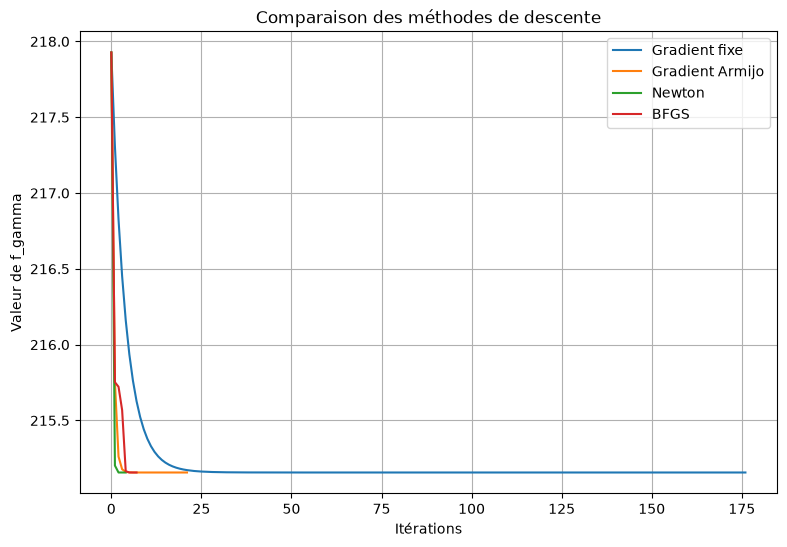

In [11]:
gamma = 0.1
plt.figure(figsize=(9, 6))

for nom, methode in methodes.items():
    x_opt, hist = methode(x0, gamma)

    plt.plot(hist, label=nom)

plt.xlabel("Itérations")
plt.ylabel("Valeur de f_gamma")
plt.title("Comparaison des méthodes de descente")
plt.legend()
plt.grid()
plt.show()

# Partie C Deuxième statégie : l'algorithme de Weiszfeld

### Question 1 : Condition d'optimalité

Soit $x^*$ un minimiseur de la fonction
$$
f(x)=\sum_{i=1}^{n} W_i \|x-a_i\|_2
$$

On suppose que $x^* \neq a_i$ pour tout $i \in \{1, \dots, n\}$.
La fonction $f$ est donc différentiable en $x^*$, et son gradient vaut :
$$
\nabla f(x^*) = 
\sum_{i=1}^{n} W_i \frac{x^*-a_i}{\|x^*-a_i\|_2}
$$
car 
$$
\nabla \|x-a_i\|_2= \frac{x-a_i}{\|x-a_i\|_2}
$$
On utilise ici l'optimalité
$$
\nabla f(x^*) = O
$$
$$
\Rightarrow \sum_{i=1}^{n} W_i \frac{x^*-a_i}{\|x^*-a_i\|_2}=0
$$
$$
\Leftrightarrow \sum_{i=1}^{n} \frac{W_ix^* - W_i a_i}{\|x^*-a_i\|_2}=0
$$
$$
\Leftrightarrow x^*\left( \sum_{i=1}^{n} \frac{W_i}{\|x^*-a_i\|_2} - \sum_{i=1}^{n} \frac{W_i a_i}{\|x^*-a_i\|_2} \right)=0
$$
$$
\Leftrightarrow x^* \sum_{i=1}^{n} \frac{W_i}{\|x^*-a_i\|_2}= \sum_{i=1}^{n} \frac{w_i a_i}{\|x^*-a_i\|_2}
$$

Les poids étant strictement positifs et les distances non nulle, la somme qui multiplie $x^*$ est stritement positive.
On peut donc diviser par celle-ci, ce qui donne : 
$$
\boxed{x^* = \frac{\displaystyle\sum_{i=1}^{n}
\frac{w_i a_i}{\|x^*-a_i\|_2}}{\displaystyle\sum_{i=1}^{n} \frac{W_i}{\|x^*-a_i\|_2}}}
$$

Cette relation est une équation de point fixe. Elle motive la mise
à jour de Weiszfeld : remplacer $x^*$ dans le membre de droite
par l’itéré courant $x^{(k)}$ pour obtenir $x^{(k+1)}$.

### Question 2 : Implémentation de l'algorithme de Weiszfeld

**L'idée principale ici est de transformer l'expression de $x^*$ une méthode itérative.**

$$
x^* = \frac{\displaystyle\sum_{i=1}^{n}
\frac{w_i a_i}{\|x^*-a_i\|_2}}{\displaystyle\sum_{i=1}^{n} \frac{w_i}{\|x^*-a_i\|_2}}
$$

en remplaçant l'expression on a:

$$
x^{(k+1)} = \frac{\displaystyle\sum_{i=1}^{n}
\frac{w_i a_i}{\|x^{(k)}-a_i\|_2}}{\displaystyle\sum_{i=1}^{n} \frac{W_i}{\|x^{(k)}-a_i\|_2}}
$$

comme $a_i = x^{(k)}-(x^{(k)}-a_i)$

$$
\Longleftrightarrow \quad x^{(k+1)} = \frac{\displaystyle\sum_{i=1}^{n}
\frac{w_i (x^{(k)}-(x^{(k)}-a_i))}{\|x^{(k)}-a_i\|_2}}{\displaystyle\sum_{i=1}^{n} \frac{w_i}{\|x^{(k)}-a_i\|_2}}
$$


$$
\Longleftrightarrow \quad
x^{(k+1)}
=
\dfrac{
x^{(k)}
\displaystyle\sum_{i=1}^{n}
\dfrac{w_i}{\|x^{(k)}-a_i\|_2}
-
\displaystyle\sum_{i=1}^{n}
\dfrac{w_i(x^{(k)}-a_i)}{\|x^{(k)}-a_i\|_2}
}{
\displaystyle\sum_{i=1}^{n}
\dfrac{w_i}{\|x^{(k)}-a_i\|_2}
}
$$

$$
\Longleftrightarrow \quad 
x^{(k+1)} 
=
x^{(k)} 
-
\dfrac{\displaystyle\sum_{i=1}^{n} \frac{w_i(x^{(k)}-a_i)}{\|x^{(k)}-a_i\|_2}}{\displaystyle\sum_{i=1}^{n} \frac{w_i}{\|x^{(k)}-a_i\|_2}}
$$

comme 

$$
\nabla f(x^*)= \sum_{i=1}^{n} w_i \frac{x^*-a_i}{\|x^*-a_i\|_2}
$$

ainsi

$$
\nabla f(x_k)
= 
\sum_{i=1}^{n} w_i \frac{x^{(k)}-a_i}{\|x^{(k)}-a_i\|_2}
$$

Donc

$$
x^{(k+1)} 
=
x^{(k)}
-
\frac{1}{\displaystyle\sum_{i=1}^{n} \frac{w_i}{\|x^{(k)}-a_i\|_2}} \nabla f(x^{(k)})
$$

Posons 
$$
\alpha_k = 
\frac{1}{\displaystyle\sum_{i=1}^{n} \frac{w_i}{\|x^{(k)}-a_i\|_2}}
$$

alors 

$$
x^{(k+1)}
= 
x^{(k)}
-
\alpha_k
\nabla f(x_k)
$$

Cette écriture met en évidence le lien entre l'algorithme de
Weiszfeld et le gradient de la fonction objectif : lorsque
$x^{(k)}$ ne coïncide avec aucun client, le déplacement s'effectue
dans la direction opposée au gradient.

Cependant, le pas
$$
\alpha_k =
\left(
\sum_{i=1}^{n}
\frac{w_i}{\|x^{(k)}-a_i\|_2}
\right)^{-1}
$$
dépend de la position courante, des distances aux clients et
de leurs poids. Il est recalculé à chaque itération à partir
de la structure du problème, sans recherche linéaire.

Weiszfeld peut donc s'interpréter, hors des sites clients,
comme une descente de gradient à pas variable particulier.
Il ne s'agit pas d'une descente de gradient à pas fixe.

Aux sites clients, le gradient n'est pas défini et cette
interprétation ne s'applique plus. Le traitement de ces points
nécessite la version modifiée présentée ci-dessous.


### Implémentation de l'algorithme de Weiszfeld

Nous avons choisi d'implémenter l'algorithme de Weiszfeld directement à partir de la fonction objectif originale :

$$
f(x)=\sum_{i=1}^{n}w_i\|x-a_i\|_2.
$$

Contrairement aux méthodes de descente étudiées précédemment, cette approche ne nécessite pas de lisser la fonction objectif à l'aide d'un paramètre $\gamma$.

L'algorithme repose sur la formule itérative suivante :

$$
x^{(k+1)}
=
\frac{
\displaystyle\sum_{i=1}^{n}
\frac{w_i a_i}{\|x^{(k)}-a_i\|_2}
}{
\displaystyle\sum_{i=1}^{n}
\frac{w_i}{\|x^{(k)}-a_i\|_2}
}.
$$

Nous avons cependant apporté plusieurs adaptations afin de garantir une meilleure robustesse numérique et de traiter les situations particulières.

#### 1. Traitement des points non différentiables

La formule classique de Weiszfeld présente une difficulté lorsque l'itéré coïncide avec un site client :

$$
x^{(k)}=a_j.
$$

Dans ce cas, le dénominateur $\|x^{(k)}-a_j\|_2$ s'annule, ce qui entraîne une division par zéro.

Nous avons donc choisi d'utiliser une version modifiée de Weiszfeld, capable de traiter explicitement cette situation.

Lorsque l'itéré coïncide avec un ou plusieurs clients, nous calculons d'abord le poids total associé à cette position :

$$
W_x=\sum_{i:a_i=x}w_i.
$$

Nous calculons ensuite le vecteur :

$$
R(x)=
\sum_{i:a_i\neq x}
w_i\frac{a_i-x}{\|x-a_i\|_2}.
$$

Puisque la fonction objectif est convexe, la condition d'optimalité au niveau d'un site client s'écrit :

$$
\boxed{\|R(x)\|_2\leq W_x.}
$$

Si cette condition est vérifiée, le point courant est un minimiseur global et l'algorithme s'arrête.

Dans le cas contraire, nous effectuons une mise à jour modifiée :

$$
x^{(k+1)}
=
\beta_k x^{(k)}
+
(1-\beta_k)T(x^{(k)}),
$$

avec :

$$
\beta_k=\frac{W_x}{\|R(x^{(k)})\|_2},
$$

et :

$$
T(x)=
\frac{
\displaystyle\sum_{i:a_i\neq x}
\frac{w_i a_i}{\|x-a_i\|_2}
}{
\displaystyle\sum_{i:a_i\neq x}
\frac{w_i}{\|x-a_i\|_2}
}.
$$

Cette modification permet de quitter un site client non optimal sans effectuer de division par zéro.

#### 2. Stabilisation numérique des coefficients

Lorsque l'itéré ne coïncide avec aucun site client, nous utilisons la formule classique de Weiszfeld.

Cependant, les coefficients :

$$
c_i=\frac{w_i}{\|x^{(k)}-a_i\|_2}
$$

peuvent devenir très grands lorsque l'itéré se rapproche fortement d'un client.

Pour limiter ce risque numérique, nous normalisons les coefficients en introduisant :

$$
d_{\min}=\min_i\|x^{(k)}-a_i\|_2.
$$

Nous calculons alors :

$$
\boxed{
\widetilde c_i=
w_i\frac{d_{\min}}{\|x^{(k)}-a_i\|_2}.
}
$$

Cette modification ne change pas mathématiquement la mise à jour, puisque le facteur commun $d_{\min}>0$ se simplifie dans le quotient :

$$
\frac{\sum_i \widetilde c_i a_i}
{\sum_i \widetilde c_i}
=
\frac{\sum_i c_i a_i}
{\sum_i c_i}.
$$

La normalisation permet ainsi de limiter la croissance des coefficients lorsque certaines distances deviennent petites.

#### 3. Choix du critère d'arrêt

Nous utilisons un critère d'arrêt fondé sur la variation des itérés :

$$
\boxed{
\|x^{(k+1)}-x^{(k)}\|_2<\varepsilon_x.
}
$$

Pour les premières expériences, nous retenons :

$$
\varepsilon_x=10^{-8}.
$$

Ce critère permet d'interrompre les itérations lorsque la position calculée ne varie pratiquement plus.

Cependant, un faible déplacement ne garantit pas nécessairement que le minimum global est atteint. Nous considérons donc ce critère comme un indicateur de convergence numérique, et non comme une certification d'optimalité.

Nous fixons également un nombre maximal d'itérations :

$$
k_{\max}=10000,
$$

afin d'éviter une exécution excessivement longue lorsque la tolérance n'est pas atteinte.

#### 4. Enregistrement de la convergence

Afin d'étudier le comportement de l'algorithme, nous enregistrons la valeur de la fonction objectif originale à chaque itération :

$$
f(x^{(0)}),f(x^{(1)}),\ldots,f(x^{(k)}).
$$

Cet historique permettra de représenter graphiquement la convergence et d'observer la diminution de la fonction objectif.

Il servira également à comparer Weiszfeld aux méthodes de descente appliquées à la fonction lissée.

#### 5. Justification des choix d'implémentation

Notre implémentation privilégie donc trois aspects :

- **Robustesse :** traitement explicite des cas où l'itéré coïncide avec un site client.
- **Stabilité numérique :** normalisation des coefficients utilisés dans la moyenne pondérée.
- **Analyse expérimentale :** conservation de l'historique de la fonction objectif et utilisation de paramètres d'arrêt explicites.

Ces choix permettent d'étudier l'algorithme de Weiszfeld directement sur la fonction originale et de préparer sa comparaison avec les méthodes du gradient, de Newton et de BFGS.


In [12]:
import numpy as np

def weiszfeld(x0, tol=1e-8, max_iter=10000):
    x = np.array(x0, dtype=float)
    historique = [f(x)]

    for k in range(max_iter):
        distances = np.linalg.norm(A - x, axis=1)
        sur_site = distances == 0
        autres = ~sur_site

        # Cas particulier : tous les clients sont au même endroit
        if not np.any(autres):
            break

        if np.any(sur_site):
            # Moyenne pondérée des clients distincts de x
            coefficients = w[autres] / distances[autres]
            T = np.sum(
                coefficients[:, None] * A[autres], axis=0
            ) / np.sum(coefficients)

            # Poids total des clients situés exactement en x
            poids_site = np.sum(w[sur_site])

            # Attraction exercée par les autres clients
            R = np.sum(
                coefficients[:, None] * (A[autres] - x),
                axis=0
            )
            norme_R = np.linalg.norm(R)

            # Condition d'optimalité en un site client
            if norme_R <= poids_site:
                break

            # Mise à jour modifiée : quitter le site non optimal
            beta = poids_site / norme_R
            x_new = beta * x + (1 - beta) * T

        else:
            # Formule classique de Weiszfeld.
            # La normalisation évite des coefficients w_i/d_i
            # très grands lorsque x est très proche d'un client.
            coefficients = w * (np.min(distances) / distances)
            x_new = np.sum(
                coefficients[:, None] * A, axis=0
            ) / np.sum(coefficients)

        historique.append(f(x_new))

        deplacement = np.linalg.norm(x_new - x)
        x = x_new

        if deplacement < tol:
            break

    return x, np.array(historique)


### Question 2 — Étude de la convergence selon les points initiaux

Afin d'étudier la sensibilité de l'algorithme de Weiszfeld à son initialisation, nous avons choisi plusieurs points de départ présentant des caractéristiques géométriques différentes.

Les clients sont répartis dans une région délimitée par :

$$
0 \leq x_1 \leq 10,
\qquad
0 \leq x_2 \leq 9.
$$

Nous retenons les cinq initialisations suivantes :

- **Origine $(0,0)$ :** ce point se situe à la frontière de la région contenant les clients. Il permet d'étudier la convergence depuis une position excentrée.
- **Centre $(5,5)$ :** ce point se situe à proximité du centre géométrique de la région. Il permet d'étudier le comportement de l'algorithme avec une initialisation proche de la solution optimale.
- **Point éloigné $(20,20)$ :** ce point se situe en dehors de la région contenant les clients. Il permet d'évaluer la robustesse de l'algorithme lorsque l'initialisation est éloignée des sites.
- **Client 3 $(4,4)$ :** ce point coïncide exactement avec un site client. Il permet de tester la version modifiée de Weiszfeld et le traitement des points où la fonction objectif n'est pas différentiable.
- **Point proche du client 3 :** défini par $(4,4)+(10^{-8},10^{-8})$, il permet d'étudier la stabilité numérique lorsque certaines distances deviennent très petites.

Ces points permettent donc de tester à la fois la sensibilité à la position initiale, la robustesse numérique et le traitement des cas particuliers prévus dans l'énoncé.

Pour chaque initialisation, nous étudierons la position finale, la valeur de la fonction objectif originale, le nombre d'itérations et l'évolution de la fonction au cours de l'optimisation.

L'objectif est de vérifier si les différentes initialisations conduisent à une même solution numérique et d'analyser leur influence sur la vitesse de convergence.
tudions la convergence à partir de plusieur points initiaux.

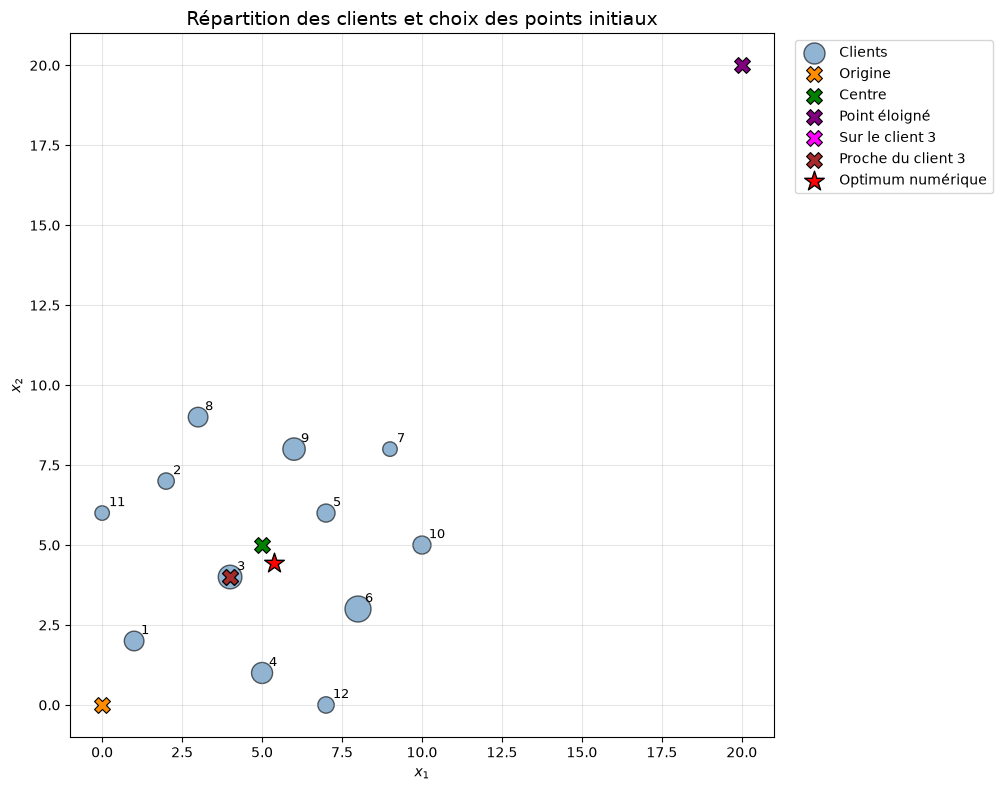

Solution numérique obtenue : [5.378001 4.43047 ]
Valeur de f : 214.19973


In [13]:

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Choix des points initiaux
# ============================================================

points_initiaux = {
    "Origine": np.array([0., 0.]),
    "Centre": np.array([5., 5.]),
    "Point éloigné": np.array([20., 20.]),
    "Sur le client 3": A[2].copy(),
    "Proche du client 3": A[2] + np.array([1e-8, 1e-8])
}

# Calcul de l'optimum numérique avec Weiszfeld
x_opt, historique = weiszfeld(np.array([5., 5.]))

# ============================================================
# Représentation graphique
# ============================================================

fig, ax = plt.subplots(figsize=(10, 8))

# Positions des clients (taille proportionnelle au poids)
ax.scatter(
    A[:, 0], A[:, 1],
    s=50 + 30 * w,
    color="steelblue",
    edgecolor="black",
    alpha=0.6,
    label="Clients"
)

# Numérotation des clients
for i, (x, y) in enumerate(A):
    ax.annotate(
        str(i + 1),
        (x, y),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

# Couleurs des points initiaux
couleurs = {
    "Origine": "darkorange",
    "Centre": "green",
    "Point éloigné": "purple",
    "Sur le client 3": "magenta",
    "Proche du client 3": "brown"
}

# Affichage des différents points de départ
for nom, point in points_initiaux.items():
    ax.scatter(
        point[0], point[1],
        s=130,
        color=couleurs[nom],
        marker="X",
        edgecolor="black",
        linewidth=0.8,
        label=nom,
        zorder=5
    )

# Position optimale estimée
ax.scatter(
    x_opt[0], x_opt[1],
    s=220,
    color="red",
    marker="*",
    edgecolor="black",
    label="Optimum numérique",
    zorder=10
)

# Mise en forme
ax.set_title(
    "Répartition des clients et choix des points initiaux",
    fontsize=14
)

ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")

ax.set_aspect("equal")
ax.grid(True, alpha=0.3)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))

plt.tight_layout()
plt.show()

print("Solution numérique obtenue :", np.round(x_opt, 6))
print("Valeur de f :", round(f(x_opt), 6))


Origine : x = [5.378001 4.43047 ], f(x) = 214.19972992, itérations = 40
Centre : x = [5.378001 4.43047 ], f(x) = 214.19972992, itérations = 33
Point éloigné : x = [5.378001 4.43047 ], f(x) = 214.19972992, itérations = 36
Sur le client 3 : x = [5.378001 4.43047 ], f(x) = 214.19972992, itérations = 38
Proche du client 3 : x = [5.378001 4.43047 ], f(x) = 214.19972992, itérations = 62


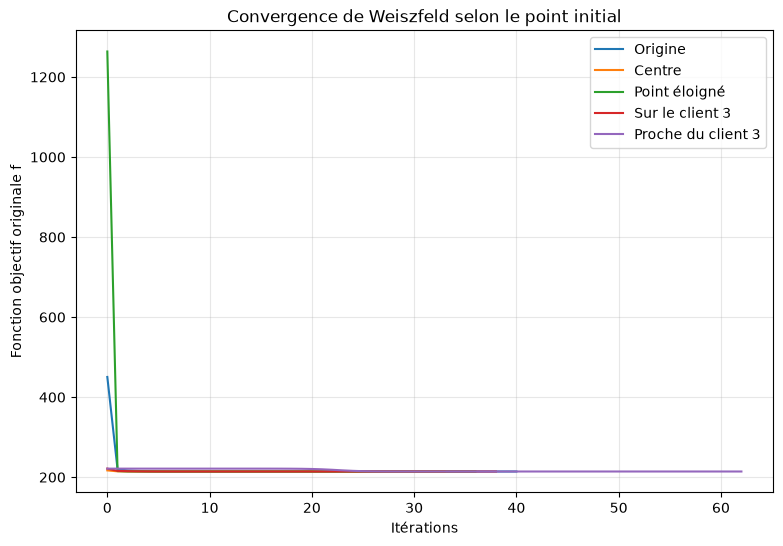

In [14]:
points_initiaux = {
    "Origine": np.array([0., 0.]),
    "Centre": np.array([5., 5.]),
    "Point éloigné": np.array([20., 20.]),
    "Sur le client 3": A[2].copy(),
    "Proche du client 3": A[2] + np.array([1e-8, 1e-8])
}

resultats_weiszfeld = {}

plt.figure(figsize=(9, 6))

for nom, depart in points_initiaux.items():
    x_opt, hist = weiszfeld(depart)
    resultats_weiszfeld[nom] = (x_opt, hist)

    print(
        f"{nom} : x = {np.round(x_opt, 6)}, "
        f"f(x) = {f(x_opt):.8f}, "
        f"itérations = {len(hist) - 1}"
    )

    plt.plot(hist, label=nom)

plt.xlabel("Itérations")
plt.ylabel("Fonction objectif originale f")
plt.title("Convergence de Weiszfeld selon le point initial")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

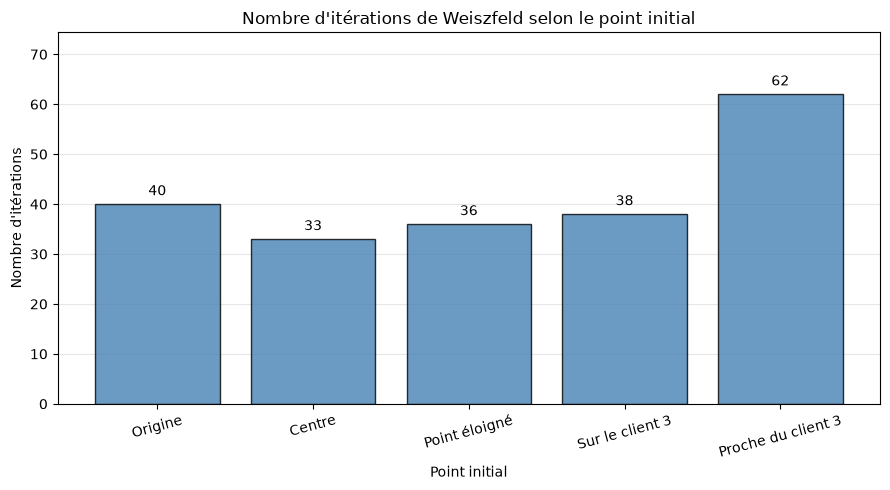

In [15]:

import matplotlib.pyplot as plt

# Récupération des résultats déjà calculés
noms = list(resultats_weiszfeld.keys())

iterations = [
    len(resultats_weiszfeld[nom][1]) - 1
    for nom in noms
]

# Graphique
fig, ax = plt.subplots(figsize=(9, 5))

barres = ax.bar(
    noms,
    iterations,
    color="steelblue",
    edgecolor="black",
    alpha=0.8
)

# Valeurs au-dessus des barres
ax.bar_label(barres, padding=4)

ax.set_title(
    "Nombre d'itérations de Weiszfeld selon le point initial"
)
ax.set_xlabel("Point initial")
ax.set_ylabel("Nombre d'itérations")

ax.set_ylim(0, max(iterations) * 1.2)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


### Analyse des résultats de convergence


#### Analyse de la sensibilité au point initial

Les premières expériences montrent que les quatre initialisations étudiées conduisent numériquement à une même position :

$$
x^*\approx(5.378001,\ 4.430470).
$$

La valeur finale de la fonction objectif est :

$$
f(x^*)\approx214.19973.
$$

En revanche, le nombre d'itérations varie selon le point initial :

| Initialisation | Nombre d'itérations |
|---|---:|
| Origine $(0,0)$ | 40 |
| Centre $(5,5)$ | 33 |
| Point éloigné $(20,20)$ | 36 |
| Client 3 $(4,4)$ | 38 |

Nous remarquons que l'initialisation au centre nécessite le plus petit nombre d'itérations parmi ces quatre expériences.

Cependant, le nombre d'itérations ne dépend pas uniquement de la distance entre le point initial et la solution optimale. Le point éloigné $(20,20)$ converge en effet en moins d'itérations que l'origine $(0,0)$.

Ce comportement s'explique par la structure de l'algorithme : les coefficients utilisés pour calculer chaque nouvelle position dépendent des distances aux différents clients et de leurs poids.

Le départ sur le client 3 permet également de vérifier que notre implémentation modifiée peut traiter une position où la fonction objectif n'est pas différentiable.

**Conclusion :** les résultats obtenus suggèrent une faible sensibilité de la solution finale au point initial, mais une sensibilité du nombre d'itérations nécessaires.

Cette conclusion reste expérimentale et concerne les initialisations retenues. Le critère d'arrêt utilisé étant fondé sur le déplacement des itérés, une vérification complémentaire de l'optimalité serait nécessaire pour certifier la précision des solutions.


### Comparaison des méthodes appliquées à la fonction lissée

In [16]:
depart = np.array([5., 5.])

x_w, hist_w = weiszfeld(depart)

print(
    f"Weiszfeld : f = {f(x_w):.8f}, "
    f"itérations = {len(hist_w) - 1}"
)

for gamma in gammas:
    print(f"\nGamma = {gamma}")

    for nom, methode in methodes.items():
        x_opt, hist = methode(depart, gamma)

        print(
            f"{nom} : f = {f(x_opt):.8f}, "
            f"itérations = {len(hist) - 1}, "
            f"distance à la solution Weiszfeld = "
            f"{np.linalg.norm(x_opt - x_w):.3e}"
        )

Weiszfeld : f = 214.19972992, itérations = 33

Gamma = 1
Gradient fixe : f = 214.22892342, itérations = 155, distance à la solution Weiszfeld = 8.831e-02
Gradient Armijo : f = 214.22892350, itérations = 16, distance à la solution Weiszfeld = 8.831e-02
Newton : f = 214.22892349, itérations = 3, distance à la solution Weiszfeld = 8.831e-02
BFGS : f = 214.22892349, itérations = 7, distance à la solution Weiszfeld = 8.831e-02

Gamma = 0.1
Gradient fixe : f = 214.20058251, itérations = 176, distance à la solution Weiszfeld = 1.517e-02
Gradient Armijo : f = 214.20058252, itérations = 21, distance à la solution Weiszfeld = 1.517e-02
Newton : f = 214.20058252, itérations = 4, distance à la solution Weiszfeld = 1.517e-02
BFGS : f = 214.20058252, itérations = 7, distance à la solution Weiszfeld = 1.517e-02

Gamma = 0.01
Gradient fixe : f = 214.19973986, itérations = 181, distance à la solution Weiszfeld = 1.639e-03
Gradient Armijo : f = 214.19973986, itérations = 22, distance à la solution Weisz

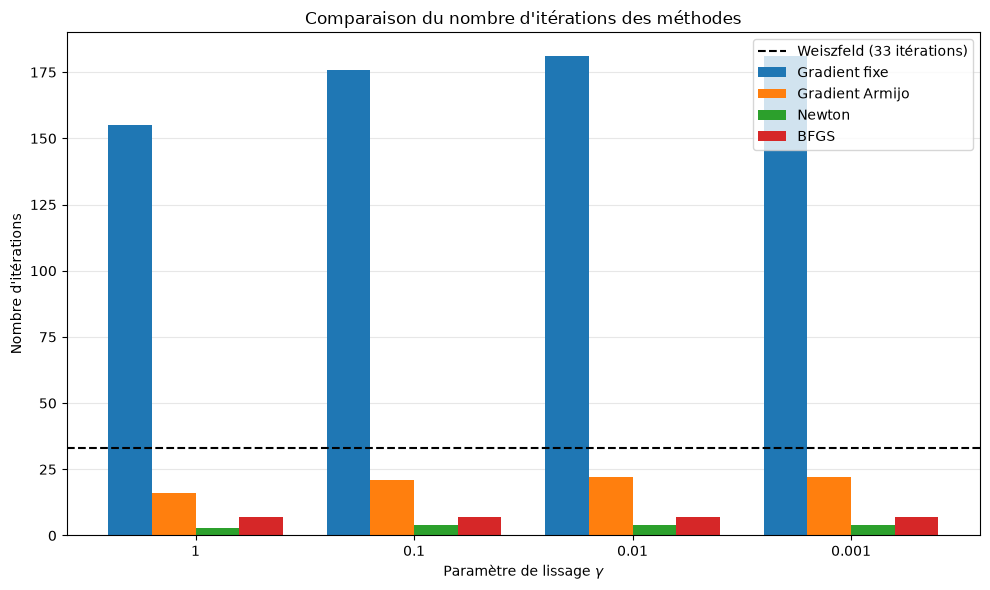

In [17]:

import numpy as np
import matplotlib.pyplot as plt

depart = np.array([5., 5.])

# Solution de référence obtenue avec Weiszfeld
x_w, hist_w = weiszfeld(depart)

# Stockage des résultats
resultats = {
    nom: {
        "iterations": [],
        "f_final": [],
        "distance": []
    }
    for nom in methodes
}

# Exécution des différentes méthodes
for gamma in gammas:
    for nom, methode in methodes.items():

        x_opt, hist = methode(depart, gamma)

        resultats[nom]["iterations"].append(len(hist) - 1)
        resultats[nom]["f_final"].append(f(x_opt))
        resultats[nom]["distance"].append(
            np.linalg.norm(x_opt - x_w)
        )

# ==================================================
# Graphique 1 : Nombre d'itérations
# ==================================================

fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(gammas))
largeur = 0.8 / len(methodes)

for j, (nom, valeurs) in enumerate(resultats.items()):
    positions = x + (j - (len(methodes)-1)/2) * largeur

    ax.bar(
        positions,
        valeurs["iterations"],
        width=largeur,
        label=nom
    )

# Ligne horizontale : Weiszfeld
ax.axhline(
    len(hist_w)-1,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label=f"Weiszfeld ({len(hist_w)-1} itérations)"
)

ax.set_xticks(x)
ax.set_xticklabels([str(g) for g in gammas])

ax.set_xlabel("Paramètre de lissage $\\gamma$")
ax.set_ylabel("Nombre d'itérations")
ax.set_title("Comparaison du nombre d'itérations des méthodes")

ax.legend()
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


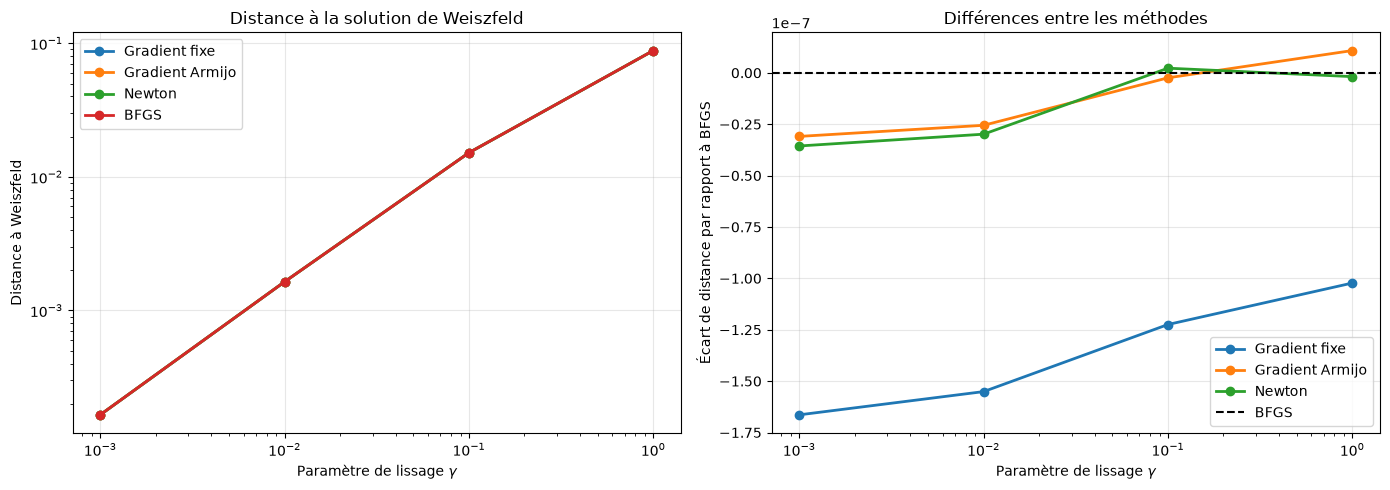

In [18]:

import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Graphique 1 : distances à Weiszfeld
for nom, valeurs in resultats.items():
    axes[0].plot(
        gammas,
        valeurs["distance"],
        marker="o",
        linewidth=2,
        label=nom
    )

axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("Paramètre de lissage $\\gamma$")
axes[0].set_ylabel("Distance à Weiszfeld")
axes[0].set_title("Distance à la solution de Weiszfeld")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Graphique 2 : écarts par rapport à BFGS
reference = np.array(resultats["BFGS"]["distance"])

for nom, valeurs in resultats.items():
    if nom == "BFGS":
        continue

    ecart = np.array(valeurs["distance"]) - reference

    axes[1].plot(
        gammas,
        ecart,
        marker="o",
        linewidth=2,
        label=nom
    )

axes[1].axhline(0, color="black",
                linestyle="--", label="BFGS")

axes[1].set_xscale("log")
axes[1].set_xlabel("Paramètre de lissage $\\gamma$")
axes[1].set_ylabel("Écart de distance par rapport à BFGS")
axes[1].set_title("Différences entre les méthodes")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


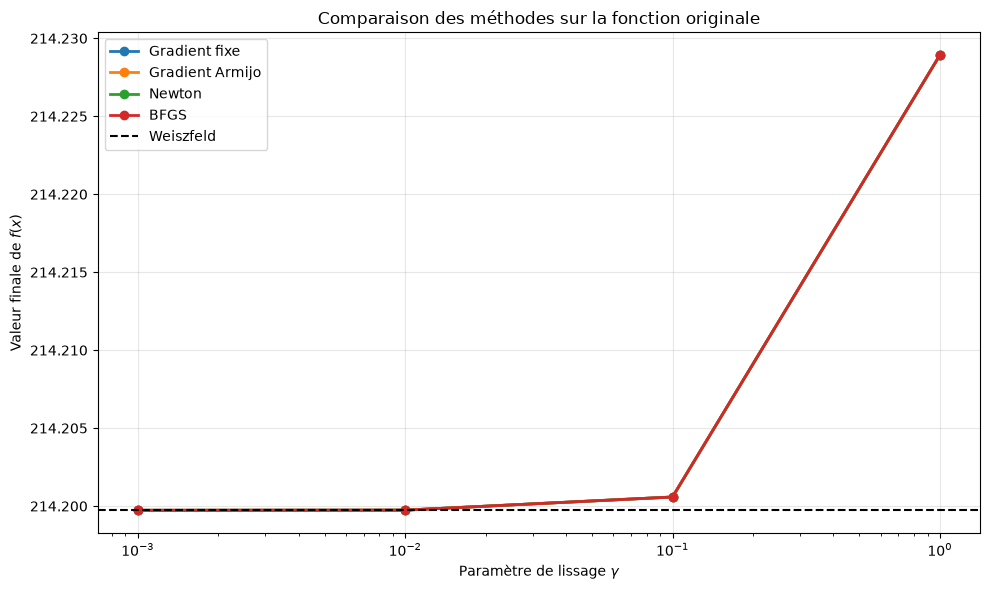

In [19]:

fig, ax = plt.subplots(figsize=(10, 6))

for nom, valeurs in resultats.items():

    ax.plot(
        gammas,
        valeurs["f_final"],
        marker="o",
        linewidth=2,
        label=nom
    )

ax.axhline(
    f(x_w),
    color="black",
    linestyle="--",
    label="Weiszfeld"
)

ax.set_xscale("log")

ax.set_xlabel("Paramètre de lissage $\\gamma$")
ax.set_ylabel("Valeur finale de $f(x)$")
ax.set_title(
    "Comparaison des méthodes sur la fonction originale"
)

ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



### Analyse comparative des méthodes

Afin de comparer les différentes méthodes d'optimisation, nous utilisons un point initial commun :

$$
x^{(0)}=(5,5).
$$

Nous comparons les méthodes du gradient à pas fixe, du gradient avec recherche linéaire d'Armijo, de Newton et de BFGS pour plusieurs valeurs du paramètre de lissage :

$$
\gamma\in\{1,\ 10^{-1},\ 10^{-2},\ 10^{-3}\}.
$$

L'algorithme de Weiszfeld est utilisé comme solution numérique de référence, puisqu'il optimise directement la fonction objectif originale sans lissage.

#### 1. Comparaison du nombre d'itérations

Les résultats montrent que les méthodes de Newton et de BFGS nécessitent généralement beaucoup moins d'itérations que les méthodes du gradient.

La descente du gradient à pas fixe présente le nombre d'itérations le plus élevé parmi les méthodes étudiées.

Cependant, le nombre d'itérations ne suffit pas pour déterminer la méthode la plus efficace, car les coûts de calcul par itération diffèrent selon les algorithmes.

#### 2. Influence du paramètre de lissage

Lorsque $\gamma$ diminue, les solutions calculées sur la fonction lissée tendent à se rapprocher de la solution obtenue par Weiszfeld.

Cela s'explique par le fait que :

$$
f_\gamma(x)\longrightarrow f(x)
\qquad\text{lorsque }\gamma\to0^+.
$$

Les expériences permettent ainsi d'étudier le compromis entre la précision de l'approximation et les difficultés numériques pouvant apparaître lorsque le lissage devient faible.

#### 3. Comparaison sur la fonction originale

Pour garantir une comparaison cohérente, nous évaluons toutes les solutions obtenues à partir de la fonction objectif originale :

$$
f(x)=\sum_{i=1}^{n}w_i\|x-a_i\|_2.
$$

Cette démarche permet de comparer les méthodes indépendamment de la fonction lissée utilisée pendant leur optimisation.

#### Conclusion

Les graphiques permettent d'étudier conjointement le nombre d'itérations, la proximité des solutions finales et la qualité des valeurs de la fonction objectif.

Une analyse complémentaire des temps de calcul et des nombres d'évaluations sera nécessaire pour déterminer quelle méthode offre le meilleur compromis entre précision et coût numérique.



# Partie D — Comparaison expérimentale

### D.1 — Définition du protocole expérimental

Dans les parties précédentes, nous avons étudié séparément les méthodes de descente appliquées à la fonction lissée et l'algorithme de Weiszfeld appliqué à la fonction originale.

Nous cherchons maintenant à réaliser une comparaison expérimentale commune afin d'évaluer leur efficacité, leur précision et leur robustesse.

Les méthodes comparées sont :

- La descente du gradient à pas fixe ;
- La descente du gradient avec recherche linéaire d'Armijo ;
- La méthode de Newton ;
- La méthode quasi-Newton BFGS ;
- L'algorithme de Weiszfeld modifié.

#### Paramètres expérimentaux

Pour assurer la reproductibilité des expériences, nous retenons un point initial commun :

$$
x^{(0)}=(5,5).
$$

Les méthodes appliquées à la fonction lissée sont testées pour :

$$
\gamma\in\{1,10^{-1},10^{-2},10^{-3}\}.
$$

Nous utilisons une tolérance de stationnarité commune aux méthodes différentiables :

$$
\|\nabla f_\gamma(x^{(k)})\|_2<10^{-6}.
$$

Pour Weiszfeld, le critère d'arrêt implémenté repose sur le déplacement :

$$
\|x^{(k+1)}-x^{(k)}\|_2<10^{-8}.
$$

Ces deux critères ne garantissent pas exactement la même précision d'optimisation. Cette différence sera prise en compte dans l'interprétation des résultats.

Les méthodes utilisent une limite maximale de 10 000 itérations.

#### Indicateurs de performance

Pour chaque expérience, nous relevons :

1. La valeur finale de la fonction objectif originale $f(x)$ ;
2. Le nombre d'itérations effectuées ;
3. Le temps d'exécution ;
4. Le nombre d'évaluations de la fonction objectif ;
5. Le nombre d'évaluations du gradient et, lorsque nécessaire, de la Hessienne ;
6. La norme finale du gradient, pour les méthodes différentiables.

Afin d'obtenir des mesures temporelles plus représentatives, chaque expérience sera répétée plusieurs fois et nous conserverons la médiane des durées mesurées.

**Comparaison des valeurs de la fonction objectif**

Bien que certaines méthodes minimisent $f_\gamma$, toutes les solutions finales seront évaluées avec :

$$
\boxed{
f(x)=\sum_{i=1}^{n}w_i\|x-a_i\|_2
}
$$

Cela permet de comparer les méthodes sur le même problème initial, indépendamment de la valeur du paramètre de lissage.


In [20]:

import numpy as np
import pandas as pd
from time import perf_counter
from IPython.display import display

# Paramètres du benchmark
depart = np.array([5., 5.])
gammas = [1, 0.1, 0.01, 0.001]

tol_benchmark = 1e-6
tol_weiszfeld = 1e-8
max_iter_benchmark = 10000
repetitions = 5

def mesurer_methode(methode, x0, gamma=None, weis=False):
    """Mesure le temps et compte les évaluations réelles."""

    compteurs = {
        "f": 0,
        "f_gamma": 0,
        "gradient": 0,
        "hessienne": 0
    }

    # Sauvegarde des fonctions d'origine
    originales = {
        nom: globals()[nom]
        for nom in ("f", "f_gamma",
                    "grad_f_gamma", "hess_f_gamma")
    }

    def instrumenter(nom):
        def fonction(*args, **kwargs):
            compteurs[nom_compteur[nom]] += 1
            return originales[nom](*args, **kwargs)
        return fonction

    nom_compteur = {
        "f": "f",
        "f_gamma": "f_gamma",
        "grad_f_gamma": "gradient",
        "hess_f_gamma": "hessienne"
    }

    temps = []
    x_final = None
    hist = None

    try:
        for _ in range(repetitions):
            for cle in compteurs:
                compteurs[cle] = 0

            # Les algorithmes appellent ces fonctions globales
            for nom in originales:
                globals()[nom] = instrumenter(nom)

            debut = perf_counter()

            if weis:
                x_final, hist = methode(
                    x0, tol=tol_weiszfeld,
                    max_iter=max_iter_benchmark
                )
            else:
                x_final, hist = methode(
                    x0, gamma,
                    tol=tol_benchmark,
                    max_iter=max_iter_benchmark
                )

            temps.append(perf_counter() - debut)

    finally:
        # Restauration, même si une exception survient
        for nom, fonction in originales.items():
            globals()[nom] = fonction

    resultat = {
        "solution": np.asarray(x_final).copy(),
        "f_originale": f(x_final),
        "iterations": len(hist) - 1,
        "temps_ms": 1000 * np.median(temps),
        "evaluations_f": (
            compteurs["f"] + compteurs["f_gamma"]
        ),
        "evaluations_grad": compteurs["gradient"],
        "evaluations_hess": compteurs["hessienne"]
    }

    if weis:
        resultat["norme_grad"] = np.nan
    else:
        resultat["norme_grad"] = np.linalg.norm(
            grad_f_gamma(x_final, gamma)
        )

    return resultat


# Exécution du benchmark
lignes = []

r = mesurer_methode(
    weiszfeld, depart, weis=True
)
lignes.append({
    "Méthode": "Weiszfeld",
    "Gamma": np.nan,
    **r
})

for gamma in gammas:
    for nom, methode in methodes.items():
        r = mesurer_methode(
            methode, depart, gamma=gamma
        )

        lignes.append({
            "Méthode": nom,
            "Gamma": gamma,
            **r
        })

df_benchmark = pd.DataFrame(lignes)

# Tableau lisible
colonnes = [
    "Méthode", "Gamma", "f_originale",
    "iterations", "temps_ms",
    "evaluations_f", "evaluations_grad",
    "evaluations_hess", "norme_grad"
]

display(
    df_benchmark[colonnes].round({
        "f_originale": 8,
        "temps_ms": 4,
        "norme_grad": 9
    })
)


,Méthode,Gamma,f_originale,iterations,temps_ms,evaluations_f,evaluations_grad,evaluations_hess,norme_grad
0,Weiszfeld,NaN,214.199730,33,3.1268,34,0,0,NaN
1,Gradient fixe,1.000,214.228923,155,6.4385,156,156,0,9.540000e-07
2,Gradient Armijo,1.000,214.228924,16,2.0051,97,17,0,8.310000e-07
3,Newton,1.000,214.228923,3,0.6950,10,4,3,2.200000e-08
4,BFGS,1.000,214.228923,7,0.8972,27,15,0,3.000000e-09
5,Gradient fixe,0.100,214.200583,176,6.4242,177,177,0,9.600000e-07
6,Gradient Armijo,0.100,214.200583,21,2.5308,127,22,0,7.230000e-07
7,Newton,0.100,214.200583,4,0.8733,13,5,4,0.000000e+00
8,BFGS,0.100,214.200583,7,0.8601,26,15,0,1.510000e-07
9,Gradient fixe,0.010,214.199740,181,6.5975,182,182,0,9.300000e-07


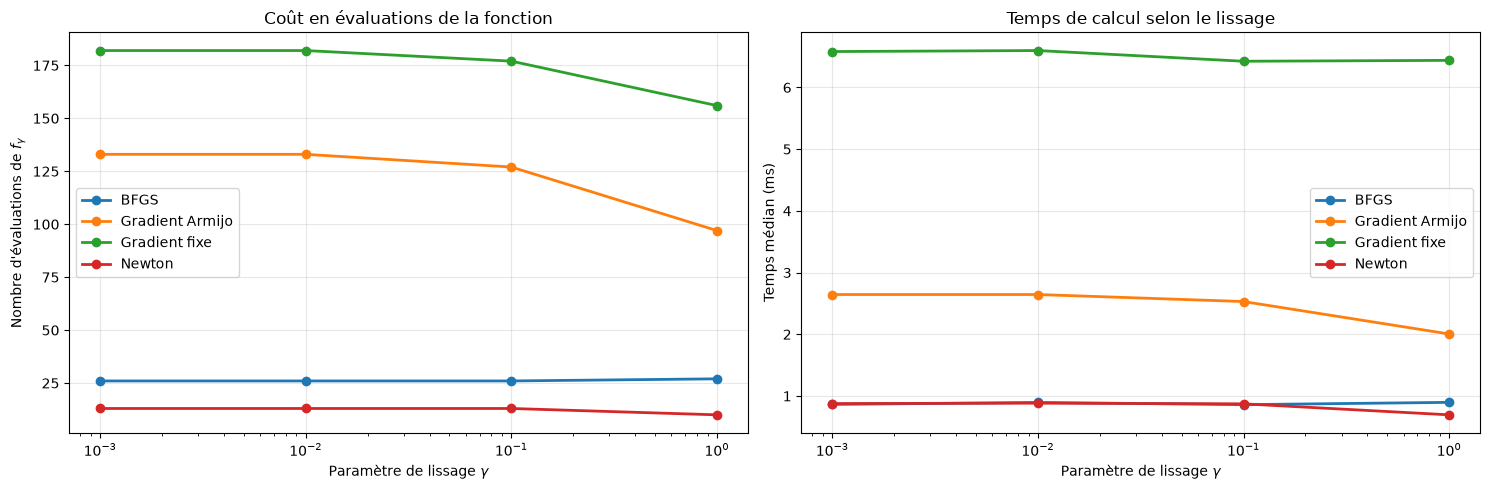

In [21]:

import matplotlib.pyplot as plt

df_lisse = df_benchmark[
    df_benchmark["Méthode"] != "Weiszfeld"
].copy()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Nombre d'évaluations de la fonction
for nom, groupe in df_lisse.groupby("Méthode"):
    groupe = groupe.sort_values("Gamma")

    axes[0].plot(
        groupe["Gamma"],
        groupe["evaluations_f"],
        marker="o",
        linewidth=2,
        label=nom
    )

axes[0].set_xscale("log")
axes[0].set_xlabel("Paramètre de lissage $\\gamma$")
axes[0].set_ylabel("Nombre d'évaluations de $f_\\gamma$")
axes[0].set_title("Coût en évaluations de la fonction")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# 2. Temps de calcul
for nom, groupe in df_lisse.groupby("Méthode"):
    groupe = groupe.sort_values("Gamma")

    axes[1].plot(
        groupe["Gamma"],
        groupe["temps_ms"],
        marker="o",
        linewidth=2,
        label=nom
    )

axes[1].set_xscale("log")
axes[1].set_xlabel("Paramètre de lissage $\\gamma$")
axes[1].set_ylabel("Temps médian (ms)")
axes[1].set_title("Temps de calcul selon le lissage")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()


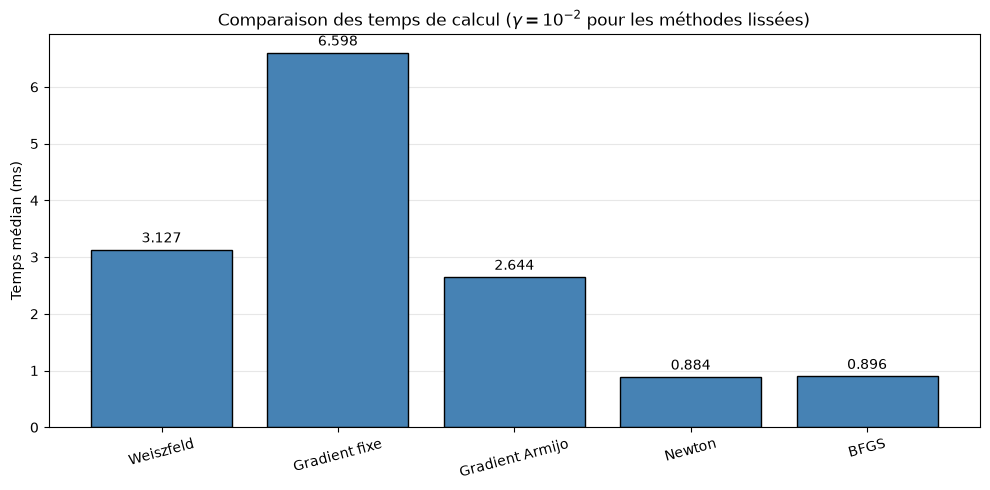

In [22]:

gamma_ref = 0.01

df_comparaison = df_benchmark[
    df_benchmark["Gamma"].eq(gamma_ref)
    | df_benchmark["Méthode"].eq("Weiszfeld")
].copy()

fig, ax = plt.subplots(figsize=(10, 5))

barres = ax.bar(
    df_comparaison["Méthode"],
    df_comparaison["temps_ms"],
    color="steelblue",
    edgecolor="black"
)

ax.bar_label(barres, fmt="%.3f", padding=3)

ax.set_title(
    "Comparaison des temps de calcul "
    r"($\gamma=10^{-2}$ pour les méthodes lissées)"
)
ax.set_ylabel("Temps médian (ms)")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()



### D.3 — Analyse du coût numérique

La comparaison du nombre d'itérations ne permet pas, à elle seule, de déterminer la méthode la plus efficace.

En effet, les opérations effectuées à chaque itération diffèrent selon les algorithmes :

- **Gradient à pas fixe :** une évaluation du gradient, suivie d'une mise à jour avec un pas constant.
- **Gradient avec Armijo :** une évaluation du gradient et plusieurs évaluations possibles de la fonction objectif lors de la recherche linéaire.
- **Newton :** calcul du gradient, de la Hessienne et résolution d'un système linéaire, avec recherche linéaire dans notre implémentation.
- **BFGS :** approximation de l'inverse de la Hessienne, sans calcul explicite de celle-ci, avec recherche linéaire.
- **Weiszfeld :** calcul des distances et d'une moyenne pondérée des positions des clients.

Nous comparons donc le coût numérique à l'aide du temps d'exécution et du nombre d'évaluations des différentes fonctions.

Le temps de calcul est mesuré en millisecondes et correspond à la médiane de plusieurs exécutions.

Ces mesures permettent de déterminer si la diminution du nombre d'itérations se traduit effectivement par un gain en temps de calcul.

Il faut cependant rappeler que le problème étudié comporte seulement deux variables et douze clients.

Les différences temporelles peuvent ainsi être faibles et sensibles aux surcoûts de Python et aux conditions d'exécution.

Les résultats devront donc être interprétés conjointement avec le nombre d'évaluations et la précision finale obtenue.


Initialisation,Centre,Client 3,Origine,Proche client 3,Éloigné
Méthode,,,,,
BFGS,7,7,7,7,9
Gradient Armijo,22,25,21,25,25
Gradient fixe,181,211,224,211,249
Newton,4,5,6,5,11
Weiszfeld,33,38,40,62,36


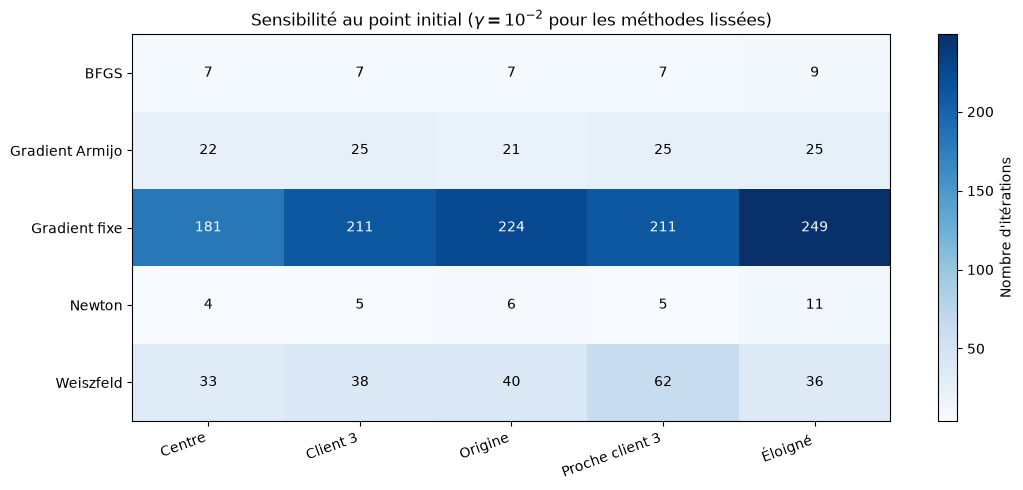

In [23]:

gamma_ref = 0.01

points_benchmark = {
    "Origine": np.array([0., 0.]),
    "Centre": np.array([5., 5.]),
    "Éloigné": np.array([20., 20.]),
    "Client 3": A[2].copy(),
    "Proche client 3": A[2] + np.array([1e-8, 1e-8])
}

lignes_sensibilite = []

for nom_point, point in points_benchmark.items():

    # Weiszfeld
    x_opt, hist = weiszfeld(
        point, tol=tol_weiszfeld,
        max_iter=max_iter_benchmark
    )

    lignes_sensibilite.append({
        "Initialisation": nom_point,
        "Méthode": "Weiszfeld",
        "Itérations": len(hist)-1,
        "f finale": f(x_opt)
    })

    # Méthodes différentiables
    for nom, methode in methodes.items():

        x_opt, hist = methode(
            point, gamma_ref,
            tol=tol_benchmark,
            max_iter=max_iter_benchmark
        )

        lignes_sensibilite.append({
            "Initialisation": nom_point,
            "Méthode": nom,
            "Itérations": len(hist)-1,
            "f finale": f(x_opt)
        })

df_sensibilite = pd.DataFrame(lignes_sensibilite)

# Tableau comparatif
tableau_iterations = df_sensibilite.pivot(
    index="Méthode",
    columns="Initialisation",
    values="Itérations"
)

display(tableau_iterations)

# Heatmap du nombre d'itérations
fig, ax = plt.subplots(figsize=(11, 5))

im = ax.imshow(
    tableau_iterations.values,
    cmap="Blues",
    aspect="auto"
)

ax.set_xticks(range(len(tableau_iterations.columns)))
ax.set_xticklabels(
    tableau_iterations.columns,
    rotation=20,
    ha="right"
)

ax.set_yticks(range(len(tableau_iterations.index)))
ax.set_yticklabels(tableau_iterations.index)

for i in range(len(tableau_iterations.index)):
    for j in range(len(tableau_iterations.columns)):
        valeur = tableau_iterations.iloc[i, j]

        ax.text(
            j, i, str(int(valeur)),
            ha="center",
            va="center",
            color=(
                "white"
                if im.norm(valeur) > 0.6
                else "black"
            )
        )

fig.colorbar(im, ax=ax, label="Nombre d'itérations")

ax.set_title(
    "Sensibilité au point initial "
    r"($\gamma=10^{-2}$ pour les méthodes lissées)"
)

plt.tight_layout()
plt.show()



### D.4 — Sensibilité aux points initiaux

Nous avons précédemment étudié l'influence du point initial sur l'algorithme de Weiszfeld.

Nous étendons maintenant cette étude aux méthodes de descente appliquées à la fonction lissée, en fixant :

$$
\gamma=10^{-2}.
$$

Nous conservons les cinq initialisations étudiées dans la partie C afin de comparer les méthodes dans des conditions géométriques identiques.

Pour chaque méthode, nous relevons le nombre d'itérations nécessaires et la valeur finale de la fonction objectif originale.

Cette expérience permet d'étudier deux aspects :

1. La sensibilité du coût de convergence au point initial.
2. La capacité des différentes méthodes à retrouver une solution numérique similaire depuis plusieurs positions de départ.

Le tableau et la carte thermique permettent d'identifier les configurations nécessitant davantage d'itérations.

Il convient de distinguer une augmentation du nombre d'itérations d'un véritable échec de convergence.

Une méthode peut nécessiter davantage d'itérations tout en obtenant une solution finale aussi précise.


In [24]:

def certificat_f_originale(x):
    """
    Majoration de f(x) - min(f) par convexité.
    Traite également les positions des clients.
    """
    x = np.asarray(x, dtype=float)
    distances = np.linalg.norm(A - x, axis=1)

    sur_site = distances == 0
    autres = ~sur_site

    # Contribution des clients distincts de x
    g = np.zeros(2)

    if np.any(autres):
        g = np.sum(
            w[autres, None]
            * (x - A[autres])
            / distances[autres, None],
            axis=0
        )

    if np.any(sur_site):
        W = np.sum(w[sur_site])
        norme = np.linalg.norm(g)

        # Sous-gradient de norme minimale
        if norme <= W:
            g = np.zeros(2)
        else:
            g = (1 - W / norme) * g

    return max(0.0, np.max((x - A) @ g))


# Ajout au tableau du benchmark
df_benchmark["certificat_f"] = [
    certificat_f_originale(x)
    for x in df_benchmark["solution"]
]

# Identification des méthodes ayant satisfait
# leur tolérance de gradient
def statut_lissage(ligne):
    if ligne["Méthode"] == "Weiszfeld":
        return "Déplacement / condition sur site"

    if ligne["norme_grad"] < tol_benchmark:
        return "Stationnarité atteinte"

    if ligne["iterations"] >= max_iter_benchmark:
        return "Limite d'itérations"

    return "Arrêt à examiner"


df_benchmark["Statut"] = df_benchmark.apply(
    statut_lissage, axis=1
)

display(df_benchmark[[
    "Méthode", "Gamma", "f_originale",
    "iterations", "certificat_f", "Statut"
]])


,Méthode,Gamma,f_originale,iterations,certificat_f,Statut
0,Weiszfeld,NaN,214.199730,33,4.103752e-07,Déplacement / condition sur site
1,Gradient fixe,1.000,214.228923,155,3.384553e+00,Stationnarité atteinte
2,Gradient Armijo,1.000,214.228923,16,3.384558e+00,Stationnarité atteinte
3,Newton,1.000,214.228923,3,3.384557e+00,Stationnarité atteinte
4,BFGS,1.000,214.228923,7,3.384557e+00,Stationnarité atteinte
5,Gradient fixe,0.100,214.200583,176,5.631591e-01,Stationnarité atteinte
6,Gradient Armijo,0.100,214.200583,21,5.631629e-01,Stationnarité atteinte
7,Newton,0.100,214.200583,4,5.631637e-01,Stationnarité atteinte
8,BFGS,0.100,214.200583,7,5.631637e-01,Stationnarité atteinte
9,Gradient fixe,0.010,214.199740,181,6.053336e-02,Stationnarité atteinte



### D.5 — Stabilité numérique et difficultés de convergence

L'étude de la stabilité numérique consiste à examiner le comportement des algorithmes lorsque les conditions initiales et les paramètres numériques varient.

Nous distinguons plusieurs difficultés potentielles.

**Méthodes du gradient :**

Le choix du pas influence fortement la vitesse de convergence. Un pas trop petit peut ralentir les itérations, tandis qu'un pas trop grand peut entraîner des oscillations ou une divergence.

**Recherche linéaire d'Armijo :**

La recherche linéaire adapte le pas pour satisfaire une condition de décroissance suffisante. Elle peut toutefois nécessiter plusieurs évaluations de la fonction objectif, ce qui augmente le coût de chaque itération.

**Méthode de Newton :**

Newton nécessite le calcul de la Hessienne ainsi que la résolution d'un système linéaire. Lorsque le paramètre de lissage devient faible, la Hessienne peut être mal conditionnée dans certaines régions, ce qui peut affecter la stabilité numérique.

**Méthode BFGS :**

BFGS utilise une approximation de l'inverse de la Hessienne. Cette approche évite le calcul explicite de la Hessienne, mais dépend de la qualité des mises à jour de son approximation.

**Algorithme de Weiszfeld :**

La formule classique présente une singularité lorsque l'itéré coïncide avec un site client. Notre implémentation utilise une modification permettant de traiter ce cas, ainsi qu'une normalisation des coefficients pour limiter certains risques numériques.

#### Vérification de l'optimalité

Nous complétons les critères d'arrêt par un certificat fondé sur la convexité de la fonction originale :

$$
0\leq f(x)-f^*
\leq G_f(x).
$$

Un certificat faible permet de majorer l'écart à la valeur optimale, indépendamment de la méthode utilisée.

Cette vérification permet notamment de distinguer une solution effectivement précise d'un algorithme ayant simplement interrompu ses itérations.

Les résultats seront interprétés en tenant compte des limites de précision numérique et du coût de calcul.



### D.6 — Synthèse du benchmark

Les expériences réalisées permettent de comparer les cinq méthodes selon plusieurs critères : la précision finale, le nombre d'itérations, le temps d'exécution, le coût en évaluations et la sensibilité au point initial.

Les premiers résultats montrent que les méthodes de Newton et BFGS nécessitent généralement moins d'itérations que les méthodes du gradient.

Cependant, cette différence ne suffit pas pour désigner la méthode la plus efficace, puisque le coût d'une itération dépend des opérations réalisées.

Nous observons également que la diminution du paramètre de lissage permet de rapprocher les solutions des méthodes différentiables de celle obtenue directement sur la fonction originale.

L'algorithme de Weiszfeld présente l'avantage de ne pas introduire d'erreur de lissage et d'exploiter directement la structure du problème de Fermat-Weber.

Le choix de la méthode doit donc reposer sur un compromis entre :

- La précision obtenue sur la fonction originale ;
- Le coût numérique réel ;
- La sensibilité aux conditions initiales ;
- La stabilité de l'algorithme.

Les résultats de cette comparaison serviront de base à la recommandation formulée dans la partie E.


# Partie E - Analyse critique et recommandation

In [25]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from time import perf_counter
from IPython.display import display

In [26]:
depart = np.array([5., 5.])
gammas_E = [1, 0.1, 0.01, 0.001]

# Mesure de la durée médiane de 5 exécutions
def mesurer_execution(fonction, *args, repetitions=5):
    durees = []

    for _ in range(repetitions):
        debut = perf_counter()
        x, hist = fonction(*args)
        durees.append(perf_counter() - debut)

    return x, hist, 1000 * np.median(durees)


# Référence : optimisation sans lissage
x_w, hist_w, temps_w = mesurer_execution(
    weiszfeld, depart
)
f_w = f(x_w)

lignes = [{
    "Méthode": "Weiszfeld",
    "Gamma": np.nan,
    "Itérations": len(hist_w) - 1,
    "f originale": f_w,
    "Distance Weiszfeld": 0.0,
    "Temps (ms)": temps_w
}]

# Méthodes de descente sur f_gamma
for gamma in gammas_E:
    for nom, methode in methodes.items():

        x_opt, hist, temps = mesurer_execution(
            methode, depart, gamma
        )

        lignes.append({
            "Méthode": nom,
            "Gamma": gamma,
            "Itérations": len(hist) - 1,
            "f originale": f(x_opt),
            "Distance Weiszfeld":
                np.linalg.norm(x_opt - x_w),
            "Temps (ms)": temps
        })

df_E = pd.DataFrame(lignes)

display(df_E.round(8))


,Méthode,Gamma,Itérations,f originale,Distance Weiszfeld,Temps (ms)
0,Weiszfeld,NaN,33,214.199730,0.000000,3.546453
1,Gradient fixe,1.000,155,214.228923,0.088312,6.196012
2,Gradient Armijo,1.000,16,214.228924,0.088312,2.163009
3,Newton,1.000,3,214.228923,0.088312,0.874304
4,BFGS,1.000,7,214.228923,0.088312,0.993821
5,Gradient fixe,0.100,176,214.200583,0.015168,6.450360
6,Gradient Armijo,0.100,21,214.200583,0.015168,2.875453
7,Newton,0.100,4,214.200583,0.015168,2.310639
8,BFGS,0.100,7,214.200583,0.015168,1.513761
9,Gradient fixe,0.010,181,214.199740,0.001639,6.445213


### E. 1 - Efficacité des méthodes

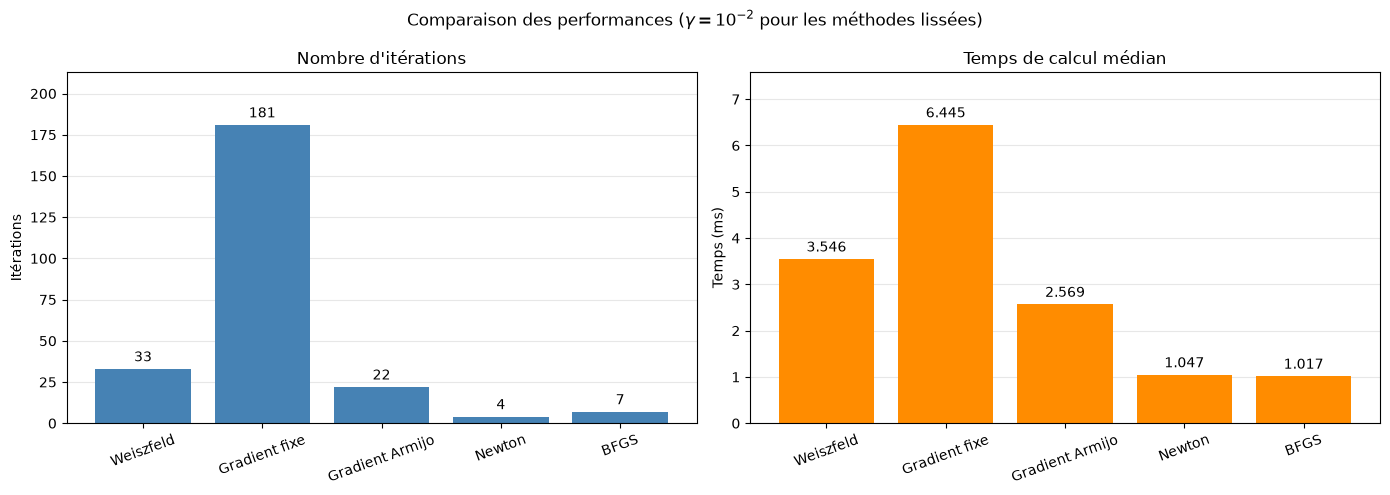

In [27]:

gamma_ref = 0.01

comparaison = df_E[
    df_E["Gamma"].eq(gamma_ref)
    | df_E["Méthode"].eq("Weiszfeld")
].copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Graphique 1 : nombre d'itérations
barres1 = axes[0].bar(
    comparaison["Méthode"],
    comparaison["Itérations"],
    color="steelblue"
)

axes[0].bar_label(barres1, padding=3)
axes[0].set_title("Nombre d'itérations")
axes[0].set_ylabel("Itérations")
axes[0].grid(axis="y", alpha=0.3)
axes[0].set_axisbelow(True)

# Graphique 2 : temps de calcul
barres2 = axes[1].bar(
    comparaison["Méthode"],
    comparaison["Temps (ms)"],
    color="darkorange"
)

axes[1].bar_label(
    barres2, fmt="%.3f", padding=3
)
axes[1].set_title("Temps de calcul médian")
axes[1].set_ylabel("Temps (ms)")
axes[1].grid(axis="y", alpha=0.3)
axes[1].set_axisbelow(True)

for ax in axes:
    ax.tick_params(axis="x", labelrotation=20)
    ax.set_ylim(0, ax.get_ylim()[1] * 1.12)

fig.suptitle(
    "Comparaison des performances "
    r"($\gamma=10^{-2}$ pour les méthodes lissées)"
)

plt.tight_layout()
plt.show()



### E.1 — Quelle méthode semble la plus efficace ?

Afin de déterminer la méthode la plus efficace, nous comparons le nombre d'itérations, le temps de calcul et la précision finale obtenue sur la fonction objectif originale.

Nous considérons le point initial commun :

$$
x^{(0)}=(5,5)
$$

et, pour les méthodes lissées :

$$
\gamma=10^{-2}.
$$

#### Comparaison du nombre d'itérations

Les résultats montrent des différences importantes entre les méthodes.

La méthode de Newton nécessite seulement **4 itérations**, contre **7 pour BFGS**, **22 pour le gradient avec Armijo** et **181 pour le gradient à pas fixe**.

L'algorithme de Weiszfeld nécessite quant à lui **33 itérations** pour satisfaire son critère d'arrêt.

La méthode de Newton est donc la plus performante selon le seul nombre d'itérations dans cette configuration.

#### Comparaison du coût de calcul

Le nombre d'itérations ne constitue toutefois pas un indicateur suffisant.

En effet, la méthode de Newton nécessite le calcul de la Hessienne :

$$
H_\gamma(x)=\nabla^2 f_\gamma(x)
$$

ainsi que la résolution du système :

$$
H_\gamma(x^{(k)})d_k
=
-\nabla f_\gamma(x^{(k)}).
$$

BFGS évite le calcul explicite de cette Hessienne, tandis que les méthodes du gradient utilisent des opérations plus simples à chaque itération.

Nous complétons donc cette comparaison par les temps d'exécution mesurés expérimentalement.

#### Interprétation

Les résultats suggèrent que les méthodes de second ordre, en particulier Newton et BFGS, sont particulièrement efficaces en nombre d'itérations pour le problème étudié.

Cependant, il est nécessaire de tenir compte du temps de calcul, du coût des évaluations et de la précision finale pour identifier la méthode la plus adaptée.

Notre problème étant de petite dimension ($x\in\mathbb{R}^2$), le coût de calcul de la Hessienne reste relativement limité.

La conclusion sur la méthode la plus efficace dépendra donc de la comparaison des temps mesurés et non uniquement du nombre d'itérations.


### E. 2 - Effet du paramètre de lissage

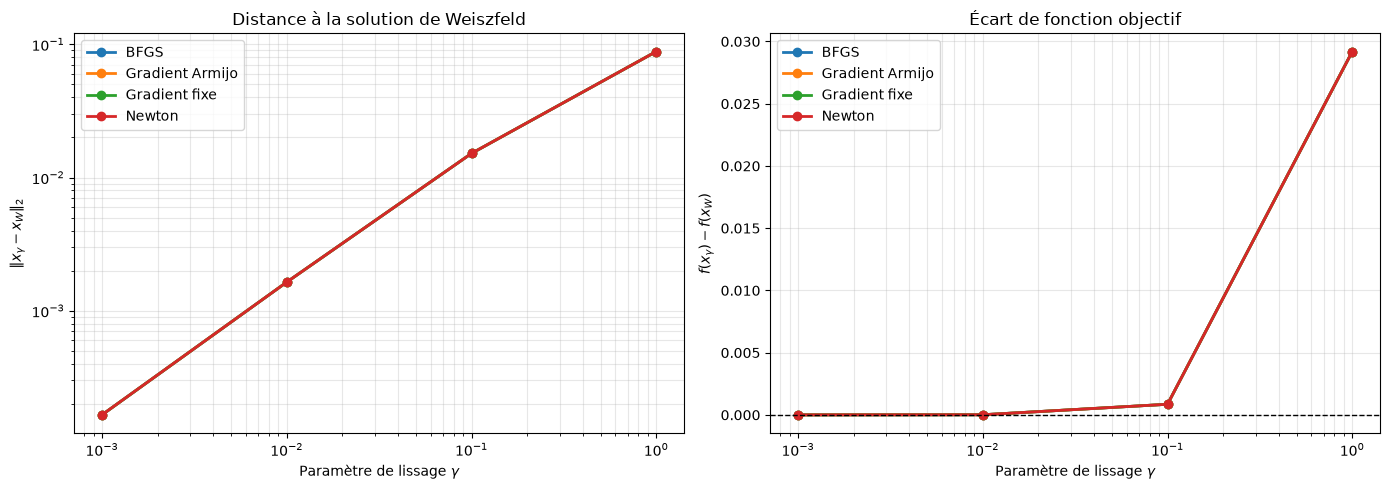

In [28]:

df_lisse_E = df_E[
    df_E["Méthode"] != "Weiszfeld"
].copy()

# Écart signé de valeur objectif à la référence
df_lisse_E["Écart f"] = (
    df_lisse_E["f originale"] - f_w
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for nom, groupe in df_lisse_E.groupby("Méthode"):

    groupe = groupe.sort_values("Gamma")

    axes[0].plot(
        groupe["Gamma"],
        groupe["Distance Weiszfeld"],
        marker="o",
        linewidth=2,
        label=nom
    )

    axes[1].plot(
        groupe["Gamma"],
        groupe["Écart f"],
        marker="o",
        linewidth=2,
        label=nom
    )

# Distance à la référence
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel(r"Paramètre de lissage $\gamma$")
axes[0].set_ylabel(r"$\|x_\gamma-x_W\|_2$")
axes[0].set_title("Distance à la solution de Weiszfeld")

# Écart de valeur de la fonction originale
axes[1].set_xscale("log")
axes[1].axhline(0, color="black",
                linestyle="--", linewidth=1)
axes[1].set_xlabel(r"Paramètre de lissage $\gamma$")
axes[1].set_ylabel(r"$f(x_\gamma)-f(x_W)$")
axes[1].set_title("Écart de fonction objectif")

for ax in axes:
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()



### E.2 — Quel est l'effet du paramètre de lissage $\gamma$ ?

Le paramètre de lissage intervient dans l'approximation différentiable de la fonction objectif :

$$
f_\gamma(x)
=
\sum_{i=1}^{n}
w_i\sqrt{\|x-a_i\|_2^2+\gamma}.
$$

Nous avons étudié les valeurs :

$$
\gamma\in\{1,10^{-1},10^{-2},10^{-3}\}.
$$

#### Influence sur la précision

Lorsque $\gamma$ diminue, la fonction lissée se rapproche de la fonction originale :

$$
\lim_{\gamma\to0^+}f_\gamma(x)=f(x).
$$

De plus, pour tout $x\in\mathbb{R}^2$ :

$$
0\leq f_\gamma(x)-f(x)
\leq \sqrt{\gamma}\sum_{i=1}^{n}w_i.
$$

Cette inégalité montre que l'erreur introduite par le lissage est contrôlée par le paramètre $\gamma$.

Les résultats expérimentaux confirment cette tendance : la distance entre les solutions des méthodes lissées et la solution obtenue par Weiszfeld diminue lorsque $\gamma$ devient plus petit.

L'écart entre les valeurs de la fonction objectif originale diminue également.

#### Influence sur les propriétés numériques

Le choix de $\gamma$ présente cependant un compromis.

Lorsque $\gamma$ est relativement grand, la fonction lissée est plus régulière numériquement, mais elle constitue une approximation moins précise de la fonction originale.

À l'inverse, lorsque $\gamma$ devient très petit, l'approximation est plus fidèle, mais la Hessienne peut présenter un conditionnement défavorable dans certaines régions.

Les algorithmes peuvent alors devenir plus sensibles aux paramètres numériques et au choix du pas de descente.

#### Conclusion

Le paramètre de lissage $\gamma$ contrôle donc principalement un compromis entre la fidélité à la fonction originale et le comportement numérique des méthodes d'optimisation.

Pour notre jeu de données, les résultats montrent que la diminution de $\gamma$ permet d'obtenir une solution plus proche de celle calculée par Weiszfeld.

Le choix d'une valeur de $\gamma$ doit néanmoins prendre en compte le coût de calcul et la précision effectivement recherchée.


### E. 3 - Avantages et limites de la méthode de Weiszfeld

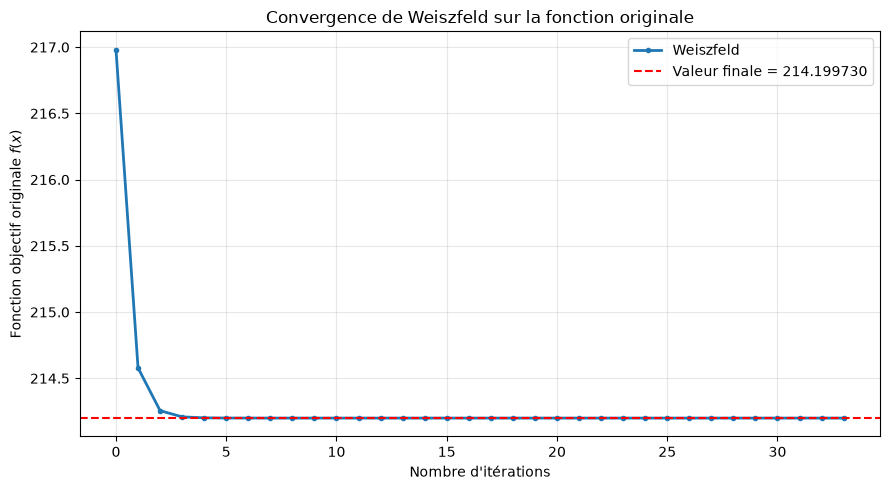

In [29]:

fig, ax = plt.subplots(figsize=(9, 5))

iterations_w = np.arange(len(hist_w))

ax.plot(
    iterations_w,
    hist_w,
    linewidth=2,
    marker="o",
    markersize=3,
    label="Weiszfeld"
)

ax.axhline(
    f_w,
    color="red",
    linestyle="--",
    label=f"Valeur finale = {f_w:.6f}"
)

ax.set_xlabel("Nombre d'itérations")
ax.set_ylabel(r"Fonction objectif originale $f(x)$")
ax.set_title("Convergence de Weiszfeld sur la fonction originale")
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()


,Point initial,Itérations,f finale,Distance référence
0,Origine,40,214.19973,0.000000e+00
1,Centre,33,214.19973,0.000000e+00
2,Éloigné,36,214.19973,3.000000e-08
3,Client 3,38,214.19973,0.000000e+00
4,Proche client 3,62,214.19973,0.000000e+00


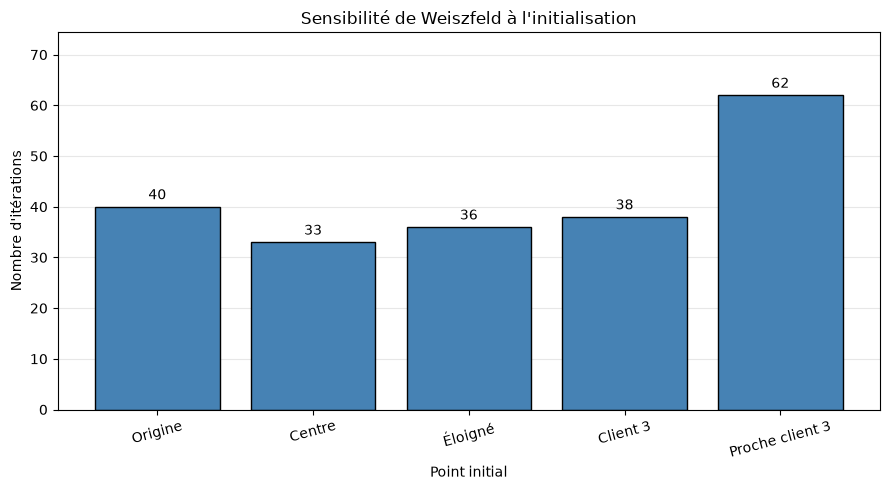

In [30]:

points_test = {
    "Origine": np.array([0., 0.]),
    "Centre": np.array([5., 5.]),
    "Éloigné": np.array([20., 20.]),
    "Client 3": A[2].copy(),
    "Proche client 3": A[2] + np.array([1e-8, 1e-8])
}

donnees = []

for nom, point in points_test.items():
    x_sol, hist = weiszfeld(point)

    donnees.append({
        "Point initial": nom,
        "Itérations": len(hist) - 1,
        "f finale": f(x_sol),
        "Distance référence": np.linalg.norm(x_sol - x_w)
    })

df_weiszfeld_E = pd.DataFrame(donnees)

display(df_weiszfeld_E.round(8))

fig, ax = plt.subplots(figsize=(9, 5))

barres = ax.bar(
    df_weiszfeld_E["Point initial"],
    df_weiszfeld_E["Itérations"],
    color="steelblue",
    edgecolor="black"
)

ax.bar_label(barres, padding=3)

ax.set_xlabel("Point initial")
ax.set_ylabel("Nombre d'itérations")
ax.set_title("Sensibilité de Weiszfeld à l'initialisation")
ax.set_ylim(
    0, df_weiszfeld_E["Itérations"].max() * 1.2
)

ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()



### E.3 — Quels avantages et quelles limites présente l'algorithme de Weiszfeld ?

L'algorithme de Weiszfeld est spécifiquement conçu pour résoudre le problème de Fermat-Weber.

Contrairement aux méthodes précédentes, il permet de minimiser directement la fonction objectif originale :

$$
f(x)=\sum_{i=1}^{n}w_i\|x-a_i\|_2
$$

sans introduire de paramètre de lissage.

#### 1. Avantages

**Absence d'erreur de lissage**

Le premier avantage de Weiszfeld est qu'il travaille directement sur $f$, contrairement aux méthodes du gradient, de Newton et de BFGS qui ont été appliquées à $f_\gamma$.

Il n'introduit donc aucune erreur d'approximation liée à $\gamma$.

**Adaptation à la structure du problème**

Weiszfeld exploite directement les positions des clients et leurs poids pour calculer une moyenne pondérée :

$$
x^{(k+1)}
=
\frac{
\displaystyle\sum_{i=1}^{n}
\frac{w_i a_i}{\|x^{(k)}-a_i\|_2}
}{
\displaystyle\sum_{i=1}^{n}
\frac{w_i}{\|x^{(k)}-a_i\|_2}
}.
$$

La méthode ne nécessite pas le calcul d'une Hessienne ni de recherche linéaire d'Armijo.

**Robustesse vis-à-vis du point initial**

Les expériences réalisées à partir de plusieurs positions initiales conduisent numériquement à la même solution :

$$
x^*\approx(5.378001,\ 4.430470)
$$

avec :

$$
f(x^*)\approx214.19973.
$$

Ces résultats suggèrent une bonne robustesse sur le jeu de données étudié.

#### 2. Limites

**Non-différentiabilité aux positions des clients**

La formule classique de Weiszfeld n'est pas définie lorsque l'itéré coïncide avec un client, car certains dénominateurs deviennent nuls.

Nous avons donc implémenté une version modifiée qui utilise la condition d'optimalité par sous-gradient lorsque le centre se trouve exactement sur un site client.

**Sensibilité numérique près des clients**

Lorsque la distance entre l'itéré et un client devient très faible, les coefficients de la formule classique peuvent devenir très grands.

Nous avons choisi de normaliser les coefficients pour limiter ce problème dans notre implémentation.

**Vitesse de convergence**

Bien que Weiszfeld soit adapté au problème, il peut nécessiter davantage d'itérations que Newton et BFGS.

Dans notre expérience réalisée depuis le point $(5,5)$, Weiszfeld nécessite 33 itérations, contre 4 pour Newton et 7 pour BFGS lorsque $\gamma=10^{-2}$.

Cette comparaison doit cependant être nuancée, car les méthodes n'optimisent pas exactement la même fonction et n'utilisent pas toutes le même critère d'arrêt.

#### 3. Conclusion

L'algorithme de Weiszfeld constitue une méthode particulièrement intéressante pour le problème de Fermat-Weber, car il exploite directement sa structure mathématique et évite l'introduction d'un paramètre de lissage.

Nos expériences montrent qu'il fournit une solution numérique stable pour les différentes initialisations testées.

Cependant, sa formule classique nécessite des précautions aux positions des clients, et sa vitesse de convergence n'est pas nécessairement supérieure à celle des méthodes de Newton ou BFGS.

Weiszfeld représente donc une alternative spécialisée pertinente aux méthodes générales d'optimisation, notamment lorsque l'on souhaite minimiser directement la fonction originale.


### E.4 — Le nombre d'itérations suffit-il pour désigner la méthode la plus performante ?

Le nombre d'itérations constitue un premier indicateur de performance, mais il ne tient pas compte du coût des opérations réalisées à chaque itération.

Afin de compléter notre analyse, nous comparons :

- Le nombre d'itérations ;
- Le temps de calcul total ;
- Le temps moyen par itération ;
- Le nombre d'évaluations de la fonction objectif, du gradient et de la Hessienne ;
- La précision obtenue sur la fonction objectif originale.

Le coût moyen par itération est estimé par :

$$
C_{\mathrm{iter}}=\frac{T_{\mathrm{calcul}}}{N_{\mathrm{iter}}}
$$

Nous conservons le point initial $x^{(0)}=(5,5)$ et le paramètre de lissage $\gamma=10^{-2}$ pour les méthodes différentiables.

In [33]:
gamma_ref = 0.01

df_E4 = df_benchmark[
    df_benchmark["Gamma"].eq(gamma_ref)
    | df_benchmark["Méthode"].eq("Weiszfeld")
].copy()

# Calcul du temps moyen par itération en microsecondes
df_E4["Temps par itération (µs)"] = (
    1000 * df_E4["temps_ms"]
    / df_E4["iterations"].replace(0, np.nan)
)

# Écart à la valeur de référence
df_E4["Écart à Weiszfeld"] = (
    df_E4["f_originale"] - f_w
)

colonnes_E4 = [
    "Méthode",
    "iterations",
    "temps_ms",
    "Temps par itération (µs)",
    "evaluations_f",
    "evaluations_grad",
    "evaluations_hess",
    "Écart à Weiszfeld",
    "certificat_f"
]

display(df_E4[colonnes_E4].round(8))

,Méthode,iterations,temps_ms,Temps par itération (µs),evaluations_f,evaluations_grad,evaluations_hess,Écart à Weiszfeld,certificat_f
0,Weiszfeld,33,3.126816,94.752000,34,0,0,0.00000,4.100000e-07
9,Gradient fixe,181,6.597523,36.450403,182,182,0,0.00001,6.053336e-02
10,Gradient Armijo,22,2.644475,120.203409,133,23,0,0.00001,6.053867e-02
11,Newton,4,0.884068,221.017000,13,5,4,0.00001,6.053790e-02
12,BFGS,7,0.895898,127.985429,26,15,0,0.00001,6.053839e-02


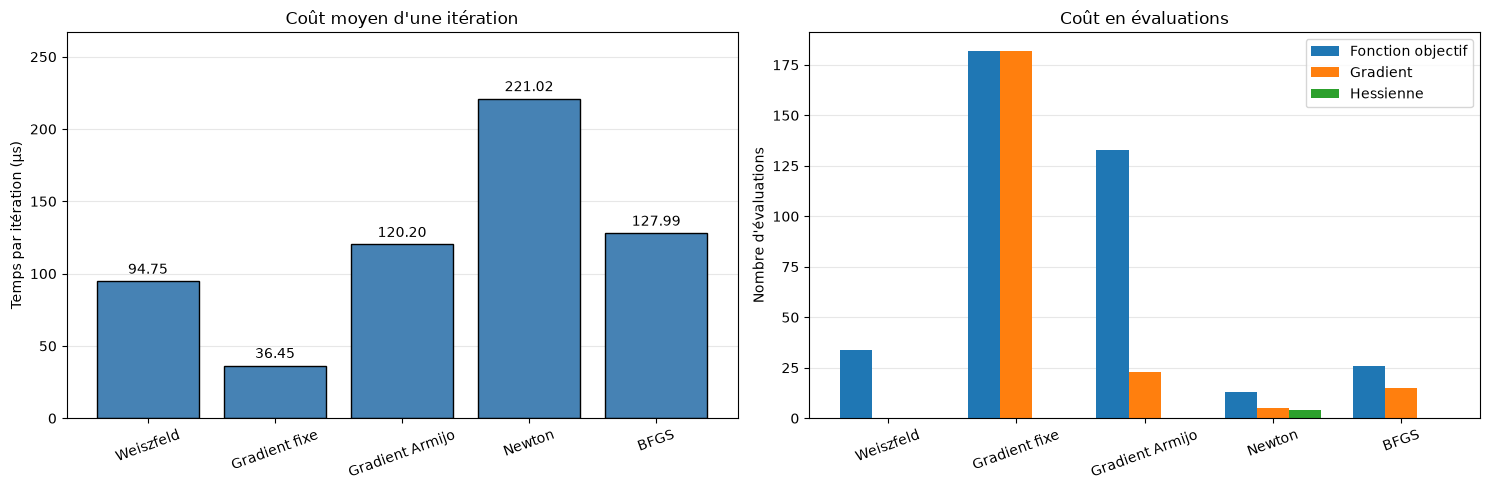

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Graphique 1 : coût moyen d'une itération
barres = axes[0].bar(
    df_E4["Méthode"],
    df_E4["Temps par itération (µs)"],
    color="steelblue",
    edgecolor="black"
)

axes[0].bar_label(barres, fmt="%.2f", padding=3)
axes[0].set_ylabel("Temps par itération (µs)")
axes[0].set_title("Coût moyen d'une itération")
axes[0].set_ylim(0, axes[0].get_ylim()[1] * 1.15)

# Graphique 2 : nombre d'évaluations
x = np.arange(len(df_E4))
largeur = 0.25

axes[1].bar(
    x - largeur,
    df_E4["evaluations_f"],
    largeur,
    label="Fonction objectif"
)

axes[1].bar(
    x,
    df_E4["evaluations_grad"],
    largeur,
    label="Gradient"
)

axes[1].bar(
    x + largeur,
    df_E4["evaluations_hess"],
    largeur,
    label="Hessienne"
)

axes[1].set_xticks(x)
axes[1].set_xticklabels(df_E4["Méthode"])
axes[1].set_ylabel("Nombre d'évaluations")
axes[1].set_title("Coût en évaluations")
axes[1].legend()

for ax in axes:
    ax.tick_params(axis="x", labelrotation=20)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

#### Analyse des résultats

Le nombre d'itérations ne suffit pas pour déterminer la méthode d'optimisation la plus performante.

En effet, le coût d'une itération dépend des opérations réalisées par chaque algorithme.

La méthode du gradient à pas fixe nécessite principalement le calcul du gradient, tandis que la méthode de Newton nécessite également le calcul de la Hessienne et la résolution d'un système linéaire.

La recherche linéaire d'Armijo peut nécessiter plusieurs évaluations de la fonction objectif au cours d'une même itération.

La méthode BFGS évite le calcul explicite de la Hessienne, mais nécessite la mise à jour d'une approximation de son inverse.

Enfin, Weiszfeld exploite directement les distances et les poids des clients, sans calcul explicite du gradient ou de la Hessienne.

#### Illustration expérimentale

Dans les résultats obtenus précédemment pour $\gamma=10^{-2}$ :

- Newton nécessite 4 itérations contre 7 pour BFGS, mais leurs temps de calcul mesurés sont très proches.
- Weiszfeld nécessite 33 itérations contre 22 pour le gradient avec Armijo, mais son temps d'exécution mesuré est inférieur.

Ces observations montrent qu'un nombre d'itérations plus faible ne garantit pas nécessairement un temps de calcul inférieur.

Il faut également tenir compte de la précision finale obtenue sur la fonction originale $f$.

Les méthodes lissées et Weiszfeld n'optimisent pas exactement la même fonction et leurs critères d'arrêt sont différents.

De plus, les compteurs d'évaluations ne représentent pas l'ensemble des opérations effectuées par les algorithmes.

#### Conclusion

Le nombre d'itérations constitue un indicateur utile, mais insuffisant.

La performance globale d'une méthode doit être évaluée en considérant simultanément :

- Le temps de calcul ;
- Le coût des opérations ;
- La précision finale ;
- La stabilité numérique ;
- La robustesse vis-à-vis du point initial.

Notre problème étant de faible dimension, les temps de calcul sont très courts et peuvent être sensibles aux conditions d'exécution.

Il convient donc de ne pas surinterpréter les faibles différences temporelles entre les méthodes.

### E.5 — Dans quelles situations privilégier une méthode générale ou une méthode spécifique ?

Les méthodes générales d'optimisation, telles que le gradient, Newton et BFGS, peuvent être appliquées à de nombreux problèmes dès lors que les hypothèses nécessaires sont satisfaites.

À l'inverse, l'algorithme de Weiszfeld exploite directement la structure particulière du problème de Fermat-Weber.

Afin d'illustrer cette différence, nous étudions l'influence du nombre de clients sur le temps de calcul des différentes méthodes.

Nous générons des jeux de données synthétiques contenant :

$$
n\in\{12,100,1000,5000\}
$$

Pour chaque jeu de données, nous conservons :

- Un point initial commun ;
- Un paramètre de lissage $\gamma=10^{-2}$ ;
- Les critères d'arrêt du benchmark ;
- Une mesure du temps médian sur cinq exécutions.

Cette expérience permet d'étudier le comportement des méthodes lorsque la taille du problème augmente.

In [36]:
def gradient_fixe_adapte(x0, gamma,
                         tol=1e-6, max_iter=10000):

    # Majoration de la constante de Lipschitz
    L = np.sum(w) / np.sqrt(gamma)

    rho = 1 / L

    return gradient_fixe(
        x0, gamma,
        rho=rho,
        tol=tol,
        max_iter=max_iter
    )

In [38]:
# Sauvegarde des données originales
A_original = A.copy()
w_original = w.copy()

rng = np.random.default_rng(42)

tailles = [12, 100, 1000, 5000]
gamma_ref = 0.01

resultats_E5 = []

try:

    for n_clients in tailles:

        # Génération des positions et des poids
        A = rng.uniform(0, 10, size=(n_clients, 2))
        w = rng.integers(1, 11, size=n_clients)

        depart_E5 = np.array([5., 5.])

        # Weiszfeld
        r = mesurer_methode(
            weiszfeld,
            depart_E5,
            weis=True
        )

        resultats_E5.append({
            "Nombre de clients": n_clients,
            "Méthode": "Weiszfeld",
            "Temps (ms)": r["temps_ms"],
            "Itérations": r["iterations"],
            "Certificat": certificat_f_originale(r["solution"])
        })

        # Méthodes générales
        methodes_E5 = methodes.copy()
        methodes_E5["Gradient fixe"] = gradient_fixe_adapte

        for nom, methode in methodes_E5.items():

            r = mesurer_methode(
                methode,
                depart_E5,
                gamma=gamma_ref
            )

            resultats_E5.append({
                "Nombre de clients": n_clients,
                "Méthode": nom,
                "Temps (ms)": r["temps_ms"],
                "Itérations": r["iterations"],
                "Certificat": certificat_f_originale(r["solution"])
            })

finally:

    # Restauration des données du problème initial
    A = A_original.copy()
    w = w_original.copy()

df_E5 = pd.DataFrame(resultats_E5)

display(df_E5.round(6))

KeyboardInterrupt: 

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))

for nom, groupe in df_E5.groupby("Méthode"):

    groupe = groupe.sort_values("Nombre de clients")

    ax.plot(
        groupe["Nombre de clients"],
        groupe["Temps (ms)"],
        marker="o",
        linewidth=2,
        label=nom
    )

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel("Nombre de clients")
ax.set_ylabel("Temps de calcul médian (ms)")
ax.set_title("Influence de la taille du problème")

ax.grid(True, which="both", alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

#### Comparaison des méthodes générales et spécifiques

**Méthodes générales d'optimisation**

Les méthodes du gradient, de Newton et de BFGS présentent l'avantage d'être polyvalentes.

Elles sont particulièrement intéressantes lorsque :

- La fonction objectif est amenée à évoluer ;
- Le problème comporte plusieurs termes de coût ;
- Aucune méthode spécifique n'est disponible ;
- On souhaite réutiliser une même stratégie d'optimisation pour différents problèmes.

La méthode de Newton est notamment intéressante lorsque la dimension du problème est faible et que la Hessienne est facilement calculable.

BFGS constitue une alternative lorsque le calcul explicite de la Hessienne devient coûteux.

Cependant, ces méthodes nécessitent certaines hypothèses de régularité. Dans notre problème, nous avons dû introduire un paramètre de lissage $\gamma$.

**Méthode spécifique de Weiszfeld**

L'algorithme de Weiszfeld est particulièrement adapté lorsque le problème conserve la structure de Fermat-Weber :

$$
f(x)=\sum_{i=1}^{n}w_i\|x-a_i\|_2.
$$

Il présente plusieurs avantages :

- Il minimise directement la fonction originale ;
- Il ne nécessite aucun paramètre de lissage ;
- Il ne nécessite pas le calcul de la Hessienne ;
- Il exploite directement les positions et les poids des clients.

Cependant, une modification importante de la fonction objectif peut rendre sa formule classique inapplicable.

#### Influence de la taille du problème

Lorsque le nombre de clients augmente, le coût de calcul des distances, du gradient et de la Hessienne augmente également.

Weiszfeld présente un coût par itération linéaire en nombre de clients lorsque la dimension spatiale est fixée.

Les méthodes générales étudiées présentent également un coût linéaire en nombre de clients pour le calcul de leurs dérivées en dimension fixée, mais leurs opérations supplémentaires et leurs nombres d'itérations diffèrent.

L'expérience permet donc de comparer leurs comportements pratiques, sans supposer qu'une méthode spécifique est systématiquement plus rapide.

#### Conclusion

Pour un problème de Fermat-Weber classique, nous privilégierions Weiszfeld pour son adaptation à la structure mathématique du problème et l'absence d'erreur de lissage.

En revanche, si le modèle devait intégrer de nouveaux coûts ou de nouvelles contraintes, nous privilégierions une méthode générale d'optimisation adaptée aux nouvelles propriétés du problème.

Le choix dépend donc à la fois de la structure mathématique, de la taille du problème et de son évolution éventuelle.

### E.6 — Précautions avant une décision d'implantation industrielle

Le problème de Fermat-Weber étudié repose sur une représentation simplifiée de la réalité industrielle.

En particulier, les positions et les poids des clients sont supposés connus et constants.

Dans une situation réelle, les volumes de marchandises peuvent évoluer en fonction de la demande, de la saisonnalité ou de l'apparition de nouveaux clients.

Il est donc nécessaire d'étudier la sensibilité de la solution optimale aux variations des données.

Nous proposons une analyse de sensibilité portant sur le client 6, qui possède le poids le plus important du jeu de données :

$$
w_6=10.
$$

Nous considérons plusieurs scénarios de variation de son poids :

$$
w_6'\in\{0.5w_6,\;0.8w_6,\;w_6,\;1.2w_6,\;1.5w_6,\;2w_6\}.
$$

Pour chaque scénario, nous recalculons la position optimale avec l'algorithme de Weiszfeld.

Nous mesurons ensuite le déplacement du centre logistique par rapport à la solution de référence :

$$
D=\|x_{\mathrm{scenario}}^*-x_{\mathrm{reference}}^*\|_2.
$$

Cette expérience permet d'évaluer la robustesse de la décision d'implantation face à une modification de la demande.

In [ ]:
# Sauvegarde des poids initiaux
w_reference = w.copy()

# Solution du problème initial
x_reference, _ = weiszfeld(np.array([5., 5.]))

# Client 6 : indice 5 en Python
indice_client = 5

facteurs = [0.5, 0.8, 1, 1.2, 1.5, 2]

resultats_E6 = []

try:

    for facteur in facteurs:

        # Modification du poids du client 6
        w = w_reference.astype(float).copy()
        w[indice_client] *= facteur

        # Nouvelle position optimale
        x_scenario, hist = weiszfeld(
            np.array([5., 5.])
        )

        # Déplacement du centre logistique
        distance = np.linalg.norm(
            x_scenario - x_reference
        )

        # Surcoût si l'entrepôt reste à sa position initiale
        surcout = f(x_reference) - f(x_scenario)

        resultats_E6.append({
            "Facteur": facteur,
            "Poids client 6": w[indice_client],
            "x1": x_scenario[0],
            "x2": x_scenario[1],
            "Déplacement": distance,
            "Coût optimal": f(x_scenario),
            "Surcoût implantation fixe": surcout
        })

finally:

    # Restauration des poids initiaux
    w = w_reference.copy()

df_E6 = pd.DataFrame(resultats_E6)

display(df_E6.round(6))

In [ ]:
fig, ax = plt.subplots(figsize=(10, 7))

# Positions des clients
ax.scatter(
    A[:, 0], A[:, 1],
    s=60*w_reference,
    color="steelblue",
    alpha=0.6,
    edgecolors="black",
    label="Clients"
)

# Identification du client 6
ax.scatter(
    A[indice_client, 0],
    A[indice_client, 1],
    s=350,
    marker="*",
    color="orange",
    edgecolors="black",
    label="Client 6"
)

# Positions optimales selon les scénarios
ax.plot(
    df_E6["x1"],
    df_E6["x2"],
    linestyle="--",
    color="red",
    alpha=0.7
)

ax.scatter(
    df_E6["x1"],
    df_E6["x2"],
    color="red",
    s=60,
    label="Solutions des scénarios"
)

# Solution de référence
ax.scatter(
    x_reference[0],
    x_reference[1],
    marker="X",
    s=150,
    color="black",
    label="Solution de référence"
)

# Annotation des différentes solutions
for _, ligne in df_E6.iterrows():

    ax.annotate(
        f'w6 = {ligne["Poids client 6"]:g}',
        (ligne["x1"], ligne["x2"]),
        xytext=(5, 8),
        textcoords="offset points",
        fontsize=9
    )

ax.set_xlabel("Coordonnée u")
ax.set_ylabel("Coordonnée v")
ax.set_title("Sensibilité de l'implantation au poids du client 6")

ax.legend()
ax.grid(alpha=0.3)
ax.set_aspect("equal")

plt.tight_layout()
plt.show()

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Déplacement du centre optimal
axes[0].plot(
    df_E6["Poids client 6"],
    df_E6["Déplacement"],
    marker="o",
    color="steelblue"
)

axes[0].set_xlabel("Poids du client 6")
axes[0].set_ylabel("Distance à la solution initiale")
axes[0].set_title("Sensibilité de la position optimale")

# Surcoût lié au maintien de l'implantation
axes[1].plot(
    df_E6["Poids client 6"],
    df_E6["Surcoût implantation fixe"],
    marker="o",
    color="darkorange"
)

axes[1].set_xlabel("Poids du client 6")
axes[1].set_ylabel("Surcoût")
axes[1].set_title("Conséquence économique d'une implantation fixe")

for ax in axes:
    ax.axvline(
        w_reference[indice_client],
        color="black",
        linestyle="--",
        label="Poids initial"
    )

    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

#### Analyse de sensibilité

La modification du poids d'un client entraîne potentiellement une modification de la position optimale du centre logistique.

Lorsque le poids du client 6 augmente, sa contribution à la fonction objectif devient plus importante.

La solution optimale tend alors à se rapprocher de ce client afin de réduire le coût total de desserte.

À l'inverse, une diminution de son poids réduit son influence sur la décision d'implantation.

Cette expérience permet également d'évaluer le surcoût associé au maintien de l'implantation initiale lorsque la demande évolue.

Une entreprise ne pouvant pas déplacer régulièrement son infrastructure, il est important de rechercher une implantation suffisamment robuste face aux variations futures de la demande.

#### 1. Validation des données

Avant toute décision industrielle, il est nécessaire de vérifier la qualité des données utilisées :

- Les coordonnées géographiques des clients ;
- Les volumes réels de marchandises ;
- La fréquence des livraisons ;
- L'évolution prévisible de la demande.

Des données incorrectes ou non représentatives peuvent conduire à une implantation inadaptée.

#### 2. Prise en compte des distances réelles

Notre modèle repose sur la distance euclidienne :

$$
\|x-a_i\|_2.
$$

Cependant, les transports utilisent des réseaux routiers dont les distances et les temps de parcours peuvent être très différents des distances à vol d'oiseau.

Il serait donc pertinent d'intégrer les distances routières, les temps de trajet, les péages et les conditions de circulation.

#### 3. Prise en compte des contraintes géographiques

Notre problème est formulé sans contrainte :

$$
\min_{x\in\mathbb{R}^2}f(x).
$$

Dans la réalité, toutes les positions ne sont pas admissibles.

Il faudrait introduire un ensemble de positions autorisées $\Omega$ et résoudre :

$$
\min_{x\in\Omega}f(x).
$$

Cet ensemble pourrait représenter les zones industrielles constructibles, les terrains disponibles ou les régions accessibles aux véhicules de transport.

L'introduction de ces contraintes pourrait modifier les propriétés mathématiques du problème et nécessiter une autre méthode d'optimisation.

#### 4. Prise en compte des coûts supplémentaires

Le coût de transport ne constitue pas le seul critère de décision.

Il faudrait également considérer :

- Le prix du terrain ;
- Le coût de construction et d'exploitation ;
- Les coûts énergétiques ;
- Les contraintes de capacité ;
- Les impacts environnementaux.

Une fonction objectif plus complète pourrait être formulée sous la forme :

$$
F(x)=C_{\mathrm{transport}}(x)
+C_{\mathrm{implantation}}(x)
+C_{\mathrm{exploitation}}(x).
$$

#### 5. Robustesse de la décision

Les paramètres du modèle peuvent évoluer dans le temps.

Une analyse de sensibilité permet d'évaluer les conséquences d'une modification des poids ou des positions des clients.

Il serait également pertinent d'étudier plusieurs scénarios économiques et d'utiliser, si nécessaire, des méthodes d'optimisation robuste ou stochastique.

#### Conclusion

La solution obtenue dans cette étude constitue une aide à la décision, mais ne peut pas être directement considérée comme une décision industrielle définitive.

Il est nécessaire de compléter le modèle mathématique par des données réelles, des contraintes géographiques, des considérations économiques et environnementales ainsi qu'une analyse des incertitudes.

La qualité d'une décision industrielle dépend donc autant de la pertinence du modèle que de la performance de l'algorithme utilisé pour le résoudre.